# Proyecto Integrador: Metodología CRISP-DM
## Predicción temprana de hospitalización en pacientes con dengue (Bucaramanga, SIVIGILA 2015 a 2025)

| Campo | Valor |
|---|---|
| **Tipo de problema** | Clasificación binaria (aprendizaje supervisado) |
| **Fuente del dataset** | Datos Abiertos Colombia: Alcaldía de Bucaramanga (SIVIGILA) |
| **Enlace al dataset** | https://www.datos.gov.co/d/qzc7-jbg3 |
| **Variable objetivo** | `pac_hos_`: ¿el paciente fue hospitalizado? (1 = Sí, 2 = No) |
| **Métrica principal** | F1-score macro |
| **Modalidad** | Individual |

Este cuaderno sigue **estrictamente las seis fases de CRISP-DM** y el orden del formato de entrega *U4_0 Formato de Entrega Trabajo Integrador*:

1. **Entendimiento del negocio**: contexto, problema, objetivos y diseño de la solución.
2. **Entendimiento de los datos**: diccionario, reglas de calidad, variable objetivo y sesgos.
3. **Preparación de los datos**: selección, ydata-profiling, limpieza, nulos, codificación, relaciones, reducción de dimensiones y balanceo.
4. **Modelamiento**: 5 modelos clásicos del curso, ensambles (votación, bagging, boosting) y ajuste de hiperparámetros con validación cruzada sobre el 70 %.
5. **Evaluación**: métricas en el conjunto de prueba (30 %) y selección justificada técnica y estadísticamente.
6. **Despliegue**: serialización del pipeline completo, predicción con datos nuevos y aplicación Streamlit.

> Cada bloque de código va precedido de su **propósito** y seguido de su **interpretación**.

## 0. Configuración del entorno

En Google Colab se instalan las **mismas versiones** de librerías con las que se entrena y se despliega el modelo. Esto es indispensable: si la versión de `scikit-learn` del entrenamiento y la de la aplicación Streamlit no coinciden, al cargar el `.joblib` se puede producir un `UnpicklingError` (ver documento de despliegue del curso).

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Mismas versiones del entrenamiento. NumPy se fija en 2.3.5 porque Colab trae NumPy 2.4,
    # que no es compatible con numba (dependencia de ydata-profiling).
    %pip install -q numpy==2.3.5 pandas==2.3.3 scikit-learn==1.9.1 imbalanced-learn==0.14.2 xgboost==3.4.1 ydata-profiling==4.18.4 "setuptools<81"
    import numpy
    if numpy.__version__ != "2.3.5":
        # NumPy ya estaba cargado con la versión anterior: se reinicia el entorno una sola vez.
        print("Se instaló NumPy 2.3.5. El entorno se reinicia: vuelve a ejecutar todo el notebook.")
        os.kill(os.getpid(), 9)
print("Ejecutando en Colab:", IN_COLAB)

Ejecutando en Colab: False


In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
import imblearn
import xgboost
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, cross_val_score)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
import joblib
from sklearn.base import clone

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")

RANDOM_STATE = 42
N_JOBS = 4          # procesos en paralelo (limitado para no agotar la memoria RAM)
np.random.seed(RANDOM_STATE)

# Estructura de carpetas del proyecto
if Path.cwd().name == "notebooks":
    os.chdir("..")
for d in ["data", "reports/figuras", "reports/tablas", "models"]:
    Path(d).mkdir(parents=True, exist_ok=True)
FIG, TAB = Path("reports/figuras"), Path("reports/tablas")

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=130, bbox_inches="tight")
    plt.show()

def guardar_tabla(df_, nombre, index=False):
    df_.to_csv(TAB / f"{nombre}.csv", index=index, encoding="utf-8-sig")
    return df_

print("Python", sys.version.split()[0])
for m in [pd, np, sklearn, imblearn, xgboost, joblib, matplotlib]:
    print(f"{m.__name__:12s} {m.__version__}")

Python 3.12.10
pandas       2.3.3
numpy        2.3.5
sklearn      1.9.1
imblearn     0.14.2
xgboost      3.4.1
joblib       1.6.0
matplotlib   3.10.0


---
# FASE 1. Entendimiento del negocio

### Descripción del negocio
El **dengue** es la arbovirosis de mayor impacto en salud pública en Colombia. Es transmitida por el mosquito *Aedes aegypti* y Bucaramanga (Santander) es zona hiperendémica. Cada caso es notificado por las instituciones de salud (UPGD) al **Sistema Nacional de Vigilancia en Salud Pública (SIVIGILA)**. La Alcaldía de Bucaramanga publica en Datos Abiertos Colombia el seguimiento de los eventos *Dengue* (cód. 210), *Dengue grave* (220) y *Mortalidad por dengue* (580), con variables sociodemográficas, de afiliación al sistema de salud, de pertenencia a grupos poblacionales, síntomas, signos de alarma, fechas clave y el desenlace del caso.

La red hospitalaria de la ciudad enfrenta **picos de demanda** durante los brotes (el año 2024 concentra el 40 % de los casos del periodo). La decisión de hospitalizar a un paciente es costosa en ambos sentidos: hospitalizar a quien no lo necesita ocupa camas escasas; enviar a casa a quien sí lo necesita puede derivar en dengue grave o muerte.

### Descripción del problema
**¿Es posible predecir, con la información disponible en la primera consulta (datos sociodemográficos, síntomas y signos de alarma, tiempo de evolución), si un paciente con dengue requerirá hospitalización?**

Un modelo de este tipo apoyaría el **triaje** y la **planeación de camas** de la Secretaría de Salud y de las IPS, y complementaría (no reemplazaría) el criterio médico y la guía clínica del Ministerio de Salud.

### Objetivos de la minería de datos
**Objetivo general:** construir un modelo de clasificación supervisada que estime si un caso notificado de dengue requerirá hospitalización, a partir de variables disponibles en la primera atención.

**Objetivos específicos (medibles):**
1. Construir un conjunto de datos limpio y libre de fuga de información (*data leakage*), aplicando reglas de calidad de negocio.
2. Comparar al menos **5 modelos clásicos** (los vistos en el curso) y **3 modelos de ensamble** con validación cruzada estratificada de 5 particiones sobre el 70 % de entrenamiento.
3. Alcanzar un **F1-macro mayor o igual a 0,85** en el conjunto de prueba (30 %) con el modelo final, con un **Recall de la clase "Hospitalizado" mayor o igual a 0,80**.
4. Desplegar el pipeline completo en una aplicación web pública en Streamlit.io que permita predecir casos nuevos.

**Criterio de éxito de negocio:** el modelo identifica correctamente al menos 8 de cada 10 pacientes que terminan hospitalizados, con una tasa de falsas alarmas razonable para apoyar el triaje.

### Diseño de la solución

| Tipo de análisis | Tipo de aprendizaje | Modelos propuestos | Métrica principal |
|---|---|---|---|
| Predictivo | Supervisado (clasificación binaria) | **Clásicos (curso):** Regresión Logística, KNN, Árbol de Decisión, SVM, Red Neuronal (MLP). **Ensambles:** Votación (suave), Bagging (árboles), Random Forest, Boosting (XGBoost) | **F1-score macro** |

**Justificación técnica de la métrica.** La clase positiva (*hospitalizado*) representa el 31,6 % de los casos, por lo que la *Accuracy* es engañosa: un modelo que siempre dijera "no hospitalizar" tendría 68 % de exactitud y sería inútil. El **F1-macro** promedia el F1 de ambas clases, equilibra precisión y sensibilidad y **da el mismo peso a los falsos positivos y a los falsos negativos de cada clase**, que es lo que se requiere cuando ambos errores tienen costo (camas ocupadas sin necesidad vs. pacientes graves enviados a casa). Como métrica de apoyo se reporta el **Recall de la clase Hospitalizado**, por su relevancia clínica.

**Flujo de la solución:** datos SIVIGILA, luego limpieza y reglas de calidad, luego selección de variables sin fuga, luego *pipeline* (imputación + escalado + codificación + SMOTE + modelo), luego validación cruzada y ajuste, luego evaluación en el conjunto de prueba, luego serialización (`joblib`), luego app Streamlit.

---
# FASE 2. Entendimiento de los datos

### 2.0 Carga del dataset
Se lee el archivo local si existe; de lo contrario se descarga directamente desde el portal oficial de Datos Abiertos Colombia. Todas las columnas se leen como texto (`dtype=str`) para **no perder información** (por ejemplo, códigos con ceros a la izquierda o el centinela `-89`) y controlar explícitamente cada conversión de tipo.

In [3]:
URL = "https://www.datos.gov.co/api/views/qzc7-jbg3/rows.csv?accessType=DOWNLOAD"
LOCAL = Path("data/dengue_bucaramanga.csv")
if LOCAL.exists():
    df_raw = pd.read_csv(LOCAL, dtype=str)
else:
    df_raw = pd.read_csv(URL, dtype=str)
    df_raw.to_csv(LOCAL, index=False)
print("Dimensiones:", df_raw.shape)
df_raw.head()

Dimensiones: (28626, 76)


,orden,cod_eve,grupo,fec_not,semana,año,grupo_etario,clasif_edad,def_clas_edad,sexo_,ocupacion_,tip_ss_,cod_ase_,aseguradora,per_etn_,estrato_,gp_discapa,gp_desplaz,gp_migrant,gp_carcela,gp_gestan,sem_ges_,gp_indigen,gp_pobicbf,gp_mad_com,gp_desmovi,gp_psiquia,gp_vic_vio,gp_otros,fuente_,cod_pais_r,cod_dpto_r,cod_mun_r,fec_con_,ini_sin_,tip_cas_,pac_hos_,fec_hos_,con_fin_,fec_def_,ajuste_,version,desplazami,famantdngu,fiebre,cefalea,dolrretroo,malgias,artralgia,erupcionr,dolor_abdo,vomito,diarrea,somnolenci,hipotensio,hepatomeg,hem_mucosa,hipotermia,aum_hemato,caida_plaq,acum_liqui,extravasac,hemorr_hem,choque,daño_organ,muesttejid,mueshigado,muesbazo,muespulmon,muescerebr,muesmiocar,muesmedula,muesriñon,clasfinal,conducta,nom_eve
0,1,210,ENFERMEDADES TRANSMITIDAS POR VECTORES,2015-04-01T00:00:00.000,1,2015,10 A 14,7 A 11,INFANCIA,M,9997,CONTRIBUTIVO,EPS130,EPS COLSANITAS,6,-89,2,2,2,2,2,-89,2,2,2,2,2,2,1,-89,170,68,1,2015-01-04T00:00:00.000,2015-01-04T00:00:00.000,2,1,2015-01-04T00:00:00.000,1,1900-01-01T00:00:00.000,3,SIVIGILA - 2015 - 15.1.0,2,2,1,1,2,1,2,2,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,DENGUE-89CON-89SIGNOS-89DE-89ALARMA,HOSPITALIZACION PISO,DENGUE
1,2,210,ENFERMEDADES TRANSMITIDAS POR VECTORES,2015-05-01T00:00:00.000,1,2015,15 A 19,18 A 28,JOVENES,M,9997,CONTRIBUTIVO,EPS037,NUEVA EPS,6,-89,2,2,2,2,2,-89,2,2,2,2,2,2,1,-89,170,68,1,2015-01-04T00:00:00.000,2015-01-02T00:00:00.000,2,2,1900-01-01T00:00:00.000,1,1900-01-01T00:00:00.000,0,SIVIGILA - 2014 - 14.2.0,2,2,1,1,2,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,DENGUE-89SIN-89SIGNOS-89DE-89ALARMA,AMBULATORIA,DENGUE
2,3,210,ENFERMEDADES TRANSMITIDAS POR VECTORES,2015-05-01T00:00:00.000,1,2015,20 A 29,18 A 28,JOVENES,F,9997,CONTRIBUTIVO,EPS002,SALUD TOTAL S.A. E.P.S.,6,-89,2,2,2,2,2,-89,2,2,2,2,2,2,1,-89,170,68,1,2015-01-05T00:00:00.000,2015-01-04T00:00:00.000,2,2,1900-01-01T00:00:00.000,1,1900-01-01T00:00:00.000,0,SIVIGILA - 2015 - 15.1.0,2,2,1,1,1,1,2,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,DENGUE-89SIN-89SIGNOS-89DE-89ALARMA,AMBULATORIA,DENGUE
3,4,210,ENFERMEDADES TRANSMITIDAS POR VECTORES,2015-07-01T00:00:00.000,1,2015,60 A 69,60 Y MAS,PERSONA MAYOR,M,9995,CONTRIBUTIVO,EPS002,SALUD TOTAL S.A. E.P.S.,6,-89,2,2,2,2,2,-89,2,2,2,2,2,2,1,-89,170,68,1,2015-01-07T00:00:00.000,2015-01-04T00:00:00.000,3,2,1900-01-01T00:00:00.000,1,1900-01-01T00:00:00.000,7,SIVIGILA - 2015 - 15.1.0,2,2,1,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,DENGUE-89SIN-89SIGNOS-89DE-89ALARMA,AMBULATORIA,DENGUE
4,5,210,ENFERMEDADES TRANSMITIDAS POR VECTORES,2015-07-01T00:00:00.000,1,2015,30 A 39,29 A 59,ADULTEZ,M,7129,CONTRIBUTIVO,EPS037,NUEVA EPS,6,-89,2,2,2,2,2,-89,2,2,2,2,2,2,1,-89,170,68,1,2015-01-05T00:00:00.000,2015-01-04T00:00:00.000,2,2,1900-01-01T00:00:00.000,1,1900-01-01T00:00:00.000,5,SIVIGILA - 2015 - 15.1.0,2,2,1,1,1,1,2,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,DENGUE-89SIN-89SIGNOS-89DE-89ALARMA,AMBULATORIA,DENGUE


In [4]:
df_raw.info(verbose=False)
print("\nRegistros por evento:")
print(df_raw["nom_eve"].value_counts())
print("\nRegistros por año:")
print(df_raw["año"].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28626 entries, 0 to 28625
Columns: 76 entries, orden to nom_eve
dtypes: object(76)
memory usage: 16.6+ MB

Registros por evento:
nom_eve
DENGUE                   28434
DENGUE GRAVE               176
MORTALIDAD POR DENGUE       16
Name: count, dtype: int64

Registros por año:
año
2015     2695
2016     2234
2017      411
2018      655
2019     2856
2020      828
2021      297
2022      953
2023     3738
2024    11541
2025     2418
Name: count, dtype: int64


### 2.1 Diccionario de datos
El diccionario documenta las **76 variables originales**: descripción oficial (metadatos del portal), tipo (numérica / categórica / fecha), rol en el modelo (entrada, salida o no usada) y, si no se usa, el motivo. Las variables marcadas como *Entrada* se transforman en la Fase 3 (por ejemplo `grupo_etario` se convierte en `edad_aprox`, y las fechas se convierten en `dias_sintomas` y `mes`).

In [5]:
DESCRIPCIONES = {
 "orden": "Consecutivo autonumérico",
 "cod_eve": "Codigo del evento de interes en salud pública",
 "grupo": "nombre del grupo de interes en salud pública",
 "fec_not": "Fecha de notificación",
 "semana": "El sistema toma la  fecha de notificación  y reporta automaticamente la semana epidemiologica correspondiente a la fecha del reporte. De 1 a 52",
 "año": "Es el año de la semana epidemiologica",
 "grupo_etario": "Los grupos etarios están determinados por la edad y la pertenencia a una etapa específica del ciclo vital humano. La clasificación por sectores etarios es la más incluyente de todas en la medida en que todos nacemos, crecemos y envejecemos de manera similar.",
 "clasif_edad": "es el rango de edades en el cual se clasifica los ciclos de vida",
 "def_clas_edad": "es la clasificacion de la edad de la victima según el ministerio de salud y proteccion social: Primera infancia, Infancia, Adolescencia, Jovenes, Adultez, Persona Mayor",
 "sexo_": "Caracteristica fisiológica al momento de nacer: M = Masculino, F = Femenino, I = Indeterminado",
 "ocupacion_": "Código de clasificación de actividad comercial",
 "tip_ss_": "Tipo de regimen de afiliación de seguridad social en salud: P = Excepción, C = Contributivo, S = Subsidiado, E = Especial, N = No asegurado, I = Indeterminado",
 "cod_ase_": "Código de la aseguradora o EPS",
 "aseguradora": "Nombre de la aseguradora",
 "per_etn_": "Pertenencia etnica: 1 = Indigenca, 2 = Rom o gitano, 3 = Raizal, 4 = Palenquero, 5 = Negro o mulato afrocolombiano, 6 = Otro",
 "estrato_": "es clasificacion socio economica de los inmuebles en donde residen",
 "gp_discapa": "Población con discapacidad: 1 = Si, 2 = No",
 "gp_desplaz": "Población  victima de desplazamiento forzado: 1 = Si, 2 = No",
 "gp_migrant": "Población migrante: 1 = Si, 2 = No",
 "gp_carcela": "Población carcelaria: 1 = Si, 2 = No",
 "gp_gestan": "Población gestante: 1 = Si, 2 = No",
 "sem_ges_": "nuimero de la semana gestacional Población indígena: 1 = Si, 2 = No",
 "gp_indigen": "Población indígena: 1 = Si, 2 = No",
 "gp_pobicbf": "Población ICBF: 1 = Si, 2 = No",
 "gp_mad_com": "Población madres comunitarias: 1 = Si, 2 = No",
 "gp_desmovi": "Población desmovilizada de grupos armados: 1 = Si, 2 = No",
 "gp_psiquia": "Población psiquiatrica: 1 = Si, 2 = No",
 "gp_vic_vio": "Población victima de violencia: 1 = Si, 2 = No",
 "gp_otros": "Otras poblaciones: 1 = Si, 2 = No",
 "fuente_": "son codigos y significan 1. Notificación rutinaria, 2. Búsqueda activa Inst., 3. Vigilancia Intensificada, 4. Búsqueda activa com., 5. Investigaciones",
 "cod_pais_r": "Código DANE del pais de residencia del evento de interes",
 "cod_dpto_r": "Código DANE del departamento de residencia del evento de interes",
 "cod_mun_r": "Código DANE del municipio de residencia del evento de interes",
 "fec_con_": "Fecha de consulta a servicio médico",
 "ini_sin_": "Fecha de inicio de síntomas",
 "tip_cas_": "tipo de caso: 1 = Sospechoso, 2 = Probable, 3 = Confirmado por laboraorio, 4 = Confirmado por clínica, 5 = Confirmado por nexo epidemiológico",
 "pac_hos_": "Paciente en servicio de hospitalización: 1 = Si, 2 = No",
 "fec_hos_": "Fecha de Hospitalización",
 "con_fin_": "Estado del usuario: 1 = Vivo, 2 = Muerto, 3 = No sabe",
 "fec_def_": "Fecha de defunción",
 "ajuste_": "Estadio en el que se encuestra el caso reportado: 0 = Sin Ajuste, 1 = Confirmación por Clínica, 2 = Confirmación por nexo epidemiológico, 3 = Confirmado por laboratorio, 6= Descartado, 7 = Otra actualización",
 "version": "Versión del sistema de vigilancia epidemiológica",
 "desplazami": "se desplazo en los ultimos 15 dias: 1 = Si, 2 = No",
 "famantdngu": "¿Algún familiar o conviviente ha tenido sintomatología de dengue en los últimos 15 días?: 1 = Si, 2 = No , 3 = desconocido",
 "fiebre": "Dengue sin signos de alarma  fiebre: 1 = Si, 2 = No",
 "cefalea": "Dengue sin signos de alarma  cefalea: 1 = Si, 2 = No",
 "dolrretroo": "Dengue sin signos de alarma  Dolor retroocular: 1 = Si, 2 = No",
 "malgias": "Dengue sin signos de alarma  Mialgias: 1 = Si, 2 = No",
 "artralgia": "Dengue sin signos de alarma  Artralgias: 1 = Si, 2 = No",
 "erupcionr": "Dengue sin signos de alarma  Erupción o rash: 1 = Si, 2 = No",
 "dolor_abdo": "Dengue con signos de alarma Dolor abdominal: 1 = Si, 2 = No",
 "vomito": "Dengue con signos de alarma Vómito: 1 = Si, 2 = No",
 "diarrea": "Dengue con signos de alarma Diarrea: 1 = Si, 2 = No",
 "somnolenci": "Dengue con signos de alarma Somnolencia o irritabilidad: 1 = Si, 2 = No",
 "hipotensio": "Dengue con signos de alarma Somnolencia o Hipotensión: 1 = Si, 2 = No",
 "hepatomeg": "Dengue con signos de alarma  Hepatomegalia: 1 = Si, 2 = No",
 "hem_mucosa": "Dengue con signos de alarma Hemorragias importantes en mucosas: 1 = Si, 2 = No",
 "hipotermia": "Dengue con signos de alarma Hipotermia: 1 = Si, 2 = No",
 "aum_hemato": "Dengue con signos de alarma Aumento hematocrito: 1 = Si, 2 = No",
 "caida_plaq": "Dengue con signos de alarma Caída de plaquetas (<100.000): 1 = Si, 2 = No",
 "acum_liqui": "Dengue con signos de alarma Acumulación de líquidos: 1 = Si, 2 = No",
 "extravasac": "Dengue grave Extravasación severa de plasma: 1 = Si, 2 = No",
 "hemorr_hem": "Dengue grave Hemorragía con compromiso hemodinámico: 1 = Si, 2 = No",
 "choque": "Dengue grave Shock por dengue: 1 = Si, 2 = No",
 "daño_organ": "Dengue grave Daño grave de órganos: 1 = Si, 2 = No",
 "muesttejid": "En caso de mortalidad por dengue muestra en tejido: 1 = Si, 2 = No",
 "mueshigado": "En caso de mortalidad por dengue muestra en Hígado: 1 = Si, 2 = No",
 "muesbazo": "En caso de mortalidad por dengue muestra en Bazo: 1 = Si, 2 = No",
 "muespulmon": "En caso de mortalidad por dengue muestra en Pulmón: 1 = Si, 2 = No",
 "muescerebr": "En caso de mortalidad por dengue muestra en Cerebro: 1 = Si, 2 = No",
 "muesmiocar": "En caso de mortalidad por dengue muestra en Miocardio: 1 = Si, 2 = No",
 "muesmedula": "En caso de mortalidad por dengue muestra en Médula: 1 = Si, 2 = No",
 "muesriñon": "En caso de mortalidad por dengue muestra en Riñon: 1 = Si, 2 = No",
 "clasfinal": "Clasificación final: 0 = no aplica, 1 = Dengue sin signos de alarma, 2. Dengue con signos de alarma, 3 = Dengue grave",
 "conducta": "Conducta: 0 = No aplica, 1 = Ambulatoria, 2 = Hospitalización piso, 3 = Unidad de cuidados intensivos, 4 = Observación, 5 = Remisión para hospitalización",
 "nom_eve": "Nombre del evento de interes en salud pública"
}

In [6]:
SINTOMAS = ["fiebre", "cefalea", "dolrretroo", "malgias", "artralgia", "erupcionr",
            "dolor_abdo", "vomito", "diarrea", "somnolenci", "hipotensio", "hepatomeg",
            "hem_mucosa", "hipotermia", "aum_hemato", "caida_plaq", "acum_liqui"]
OTRAS_BIN = ["desplazami", "famantdngu", "gp_gestan", "gp_migrant"]
SIGNOS_GRAVE = ["extravasac", "hemorr_hem", "choque", "daño_organ"]
MUESTRAS = ["muesttejid", "mueshigado", "muesbazo", "muespulmon", "muescerebr",
            "muesmiocar", "muesmedula", "muesriñon"]

ROL = {}  # variable -> (rol, motivo)
for v in SINTOMAS + OTRAS_BIN + ["sexo_", "tip_ss_", "estrato_"]:
    ROL[v] = ("Entrada", "")
ROL["grupo_etario"] = ("Entrada", "Se transforma en edad_aprox (numérica)")
ROL["fec_con_"] = ("Entrada", "Se usa para calcular dias_sintomas")
ROL["ini_sin_"] = ("Entrada", "Se usa para calcular dias_sintomas y mes")
ROL["pac_hos_"] = ("Salida", "Variable objetivo")
fuga = {"fec_hos_": "Fuga: fecha de hospitalización (revela el target)",
        "conducta": "Fuga: decisión médica final (ambulatoria/hospitalización)",
        "clasfinal": "Fuga: clasificación final posterior a la atención",
        "nom_eve": "Fuga: evento final (dengue grave/mortalidad) definido después",
        "cod_eve": "Fuga: código del evento final", "tip_cas_": "Fuga: confirmación posterior (laboratorio)",
        "ajuste_": "Fuga: ajuste posterior del caso", "con_fin_": "Fuga: desenlace (vivo/muerto)",
        "fec_def_": "Fuga: fecha de defunción"}
for v in SIGNOS_GRAVE: fuga[v] = "Fuga: signo de dengue grave registrado durante la hospitalización"
for v in MUESTRAS: fuga[v] = "Fuga: muestra de autopsia (solo casos fallecidos)"
for v, m in fuga.items(): ROL[v] = ("No usada", m)
otros = {"orden": "Identificador consecutivo", "grupo": "Constante (un solo valor)",
         "fec_not": "Fecha administrativa de notificación", "semana": "Redundante con la fecha de inicio de síntomas",
         "año": "No es serie de tiempo; además presenta deriva (ver sesgos)",
         "clasif_edad": "Redundante con grupo_etario", "def_clas_edad": "Redundante con grupo_etario",
         "ocupacion_": "855 códigos, sin catálogo y 45 % códigos genéricos",
         "cod_ase_": "Alta cardinalidad (119); su información la resume tip_ss_",
         "aseguradora": "Alta cardinalidad (134 nombres inconsistentes)",
         "per_etn_": "Casi constante (99,3 % = 6 'otro')", "sem_ges_": "99,6 % sin dato",
         "fuente_": "Variable del proceso de notificación, no del paciente",
         "cod_pais_r": "Casi constante / 15 % sin dato", "cod_dpto_r": "Casi constante (98,9 % Santander)",
         "cod_mun_r": "Casi constante (96 % Bucaramanga)", "version": "Versión del software SIVIGILA",
         "gp_otros": "Categoría residual sin significado clínico"}
for v in ["gp_discapa", "gp_desplaz", "gp_carcela", "gp_indigen", "gp_pobicbf", "gp_mad_com",
          "gp_desmovi", "gp_psiquia", "gp_vic_vio"]:
    otros[v] = "Casi constante (< 0,3 % de casos positivos)"
for v, m in otros.items(): ROL[v] = ("No usada", m)

NUMERICAS_ORIG = {"orden", "semana", "año", "estrato_", "sem_ges_"}
FECHAS_ORIG = {"fec_not", "fec_con_", "ini_sin_", "fec_hos_", "fec_def_"}
def tipo(v):
    if v in FECHAS_ORIG: return "Fecha"
    return "Num" if v in NUMERICAS_ORIG else "Cat"

diccionario = pd.DataFrame([{
    "Variable": v,
    "Descripción": DESCRIPCIONES.get(v, ""),
    "Tipo (Num/Cat)": tipo(v),
    "Entrada/Salida": ROL.get(v, ("No usada", ""))[0],
    "Observación": ROL.get(v, ("", ""))[1],
} for v in df_raw.columns])
guardar_tabla(diccionario, "2_1_diccionario")
print(diccionario["Entrada/Salida"].value_counts())
diccionario

Entrada/Salida
No usada    48
Entrada     27
Salida       1
Name: count, dtype: int64


,Variable,Descripción,Tipo (Num/Cat),Entrada/Salida,Observación
0,orden,Consecutivo autonumérico,Num,No usada,Identificador consecutivo
1,cod_eve,Codigo del evento de interes en salud pública,Cat,No usada,Fuga: código del evento final
2,grupo,nombre del grupo de interes en salud pública,Cat,No usada,Constante (un solo valor)
3,fec_not,Fecha de notificación,Fecha,No usada,Fecha administrativa de notificación
4,semana,El sistema toma la fecha de notificación y r...,Num,No usada,Redundante con la fecha de inicio de síntomas
...,...,...,...,...,...
71,muesmedula,En caso de mortalidad por dengue muestra en Mé...,Cat,No usada,Fuga: muestra de autopsia (solo casos fallecidos)
72,muesriñon,En caso de mortalidad por dengue muestra en Ri...,Cat,No usada,Fuga: muestra de autopsia (solo casos fallecidos)
73,clasfinal,"Clasificación final: 0 = no aplica, 1 = Dengue...",Cat,No usada,Fuga: clasificación final posterior a la atención
74,conducta,"Conducta: 0 = No aplica, 1 = Ambulatoria, 2 = ...",Cat,No usada,Fuga: decisión médica final (ambulatoria/hospi...


**Interpretación.** De las 76 variables, 25 son candidatas de entrada (17 síntomas/signos de alarma, 4 binarias de contexto, 3 sociodemográficas y la edad), dos fechas se usan solo para construir variables derivadas y **una es la salida** (`pac_hos_`). La mayoría de las variables descartadas lo son por **fuga de información** (describen lo que pasó *después* de decidir hospitalizar) o por ser casi constantes. La justificación detallada está en la sección 3.1.

### 2.2 Reglas de calidad
Las reglas se definen **desde el conocimiento del negocio y de los metadatos oficiales**, no a partir del mínimo y máximo observados (eso sería un error: el dataset puede contener errores, como 341 días de síntomas). Para cada regla se cuantifica cuántos registros la incumplen en los datos crudos.

| Variable | Regla | Fuente de la regla |
|---|---|---|
| `edad` (por `grupo_etario`) | 0 a 110 años; 11 grupos válidos | Clasificación del Minsalud |
| `dias_sintomas` = consulta - inicio síntomas | 0 a 30 días | La fase febril del dengue dura 2 a 7 días; más de 30 días no corresponde a dengue agudo |
| `estrato_` | 1 a 6 | Estratificación socioeconómica colombiana |
| `mes` | 1 a 12 | Calendario |
| `año` | 2015 a 2025 | Periodo publicado |
| `semana` | 1 a 53 | Semana epidemiológica |
| Síntomas, signos y grupos (desde `fiebre` hasta `gp_migrant`) | {1 = Sí, 2 = No} | Ficha de notificación SIVIGILA (metadatos) |
| `famantdngu` | {1, 2} (3 = desconocido, se trata como faltante) | Metadatos |
| `sexo_` | {M, F} | Metadatos |
| `tip_ss_` | {C, S, P, E, N, I} | Metadatos |
| `pac_hos_` | {1, 2} | Metadatos |

In [7]:
def parse_fecha(s):
    # El portal mezcla formatos ISO (2024-06-11T00:00:00.000) y dd/mm/aaaa
    iso = pd.to_datetime(s, format="ISO8601", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

REGIMEN = {"C": "C", "CONTRIBUTIVO": "C", "S": "S", "SUBSIDIADO": "S", "P": "P", "EXCEPCIÓN": "P",
           "EXCEPCIÃ“N": "P", "E": "E", "ESPECIAL": "E", "N": "N", "NO ASEGURADO": "N",
           "I": "I", "INDETERMINADO": "I"}
GRUPOS_VALIDOS = ["MENOR DE 1", "1 A 4", "5 A 9", "10 A 14", "15 A 19", "20 A 29",
                  "30 A 39", "40 A 49", "50 A 59", "60 A 69", "70 Y MAS"]
_dias = (parse_fecha(df_raw["fec_con_"]) - parse_fecha(df_raw["ini_sin_"])).dt.days

def num(s): return pd.to_numeric(s, errors="coerce")

reglas_num = [
    ("dias_sintomas", "0 a 30", _dias, 0, 30),
    ("estrato_", "1 a 6", num(df_raw["estrato_"]), 1, 6),
    ("mes (inicio síntomas)", "1 a 12", parse_fecha(df_raw["ini_sin_"]).dt.month, 1, 12),
    ("año", "2015 a 2025", num(df_raw["año"]), 2015, 2025),
    ("semana", "1 a 53", num(df_raw["semana"]), 1, 53),
]
filas = []
for var, rango, serie, lo, hi in reglas_num:
    fuera = ((serie < lo) | (serie > hi)).sum()
    nulos = serie.isna().sum()
    filas.append({"Variable": var, "Rango esperado": rango, "Mín. observado": serie.min(),
                  "Máx. observado": serie.max(), "Fuera de rango": int(fuera),
                  "Sin dato (-89/vacío)": int(nulos), "% incumple": round(100 * (fuera + nulos) / len(serie), 2)})
calidad_num = guardar_tabla(pd.DataFrame(filas), "2_2_reglas_numericas")
calidad_num

,Variable,Rango esperado,Mín. observado,Máx. observado,Fuera de rango,Sin dato (-89/vacío),% incumple
0,dias_sintomas,0 a 30,0.0,341.0,73,0,0.26
1,estrato_,1 a 6,-89.0,6.0,5864,615,22.63
2,mes (inicio síntomas),1 a 12,1.0,12.0,0,0,0.00
3,año,2015 a 2025,2015.0,2025.0,0,0,0.00
4,semana,1 a 53,1.0,53.0,0,0,0.00


In [8]:
reglas_cat = {v: ["1", "2"] for v in SINTOMAS + OTRAS_BIN}
reglas_cat.update({"sexo_": ["M", "F"], "tip_ss_": ["C", "S", "P", "E", "N", "I"],
                   "pac_hos_": ["1", "2"], "grupo_etario": GRUPOS_VALIDOS})
filas = []
for var, validas in reglas_cat.items():
    s = df_raw[var]
    invalidos = (~s.isin(validas)).sum()
    ejemplos = s[~s.isin(validas)].value_counts().head(4).to_dict()
    ejemplos = {("EXCEPCIÓN (texto dañado)" if "Ã" in str(k) else k): v for k, v in ejemplos.items()}
    filas.append({"Variable": var, "Categorías válidas": ", ".join(validas),
                  "Registros que incumplen": int(invalidos),
                  "% incumple": round(100 * invalidos / len(s), 2),
                  "Valores inválidos más frecuentes": ejemplos})
calidad_cat = guardar_tabla(pd.DataFrame(filas), "2_2_reglas_categoricas")
calidad_cat

,Variable,Categorías válidas,Registros que incumplen,% incumple,Valores inválidos más frecuentes
0,fiebre,"1, 2",1,0.00,{'3': 1}
1,cefalea,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
2,dolrretroo,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
3,malgias,"1, 2",1,0.00,{'3': 1}
4,artralgia,"1, 2",1,0.00,{'3': 1}
5,erupcionr,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
6,dolor_abdo,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
7,vomito,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
8,diarrea,"1, 2",2,0.01,"{'3': 1, '-89': 1}"
9,somnolenci,"1, 2",2,0.01,"{'3': 1, '-89': 1}"


**Interpretación.** Se confirman problemas de calidad que deben tratarse en la Fase 3:
- **Centinela `-89` (sin dato)**: afecta sobre todo a `estrato_` (aproximadamente 20 %) y a `famantdngu`; además `famantdngu` usa `3 = desconocido`.
- **Categorías inconsistentes**: `grupo_etario` aparece en minúsculas y mayúsculas (`"20 a 29"` / `"20 A 29"`); `tip_ss_` mezcla códigos y nombres (`"C"` / `"CONTRIBUTIVO"`) e incluso presenta **errores de codificación de caracteres** (la palabra EXCEPCIÓN aparece con caracteres dañados).
- **Valores fuera de dominio**: síntomas con valor `3`; `gp_gestan` con valores 3 y 4 (no definidos en los metadatos).
- **Valores atípicos imposibles**: hasta 341 días entre inicio de síntomas y consulta.
- **Formatos de fecha mixtos** (ISO y dd/mm/aaaa), que se resolvieron con un parser doble.

### 2.3 Distribución de la variable objetivo

                  Casos      %
pac_hos_                      
No hospitalizado  19589  68.43
Hospitalizado      9037  31.57
Razón de desbalance (mayoritaria/minoritaria): 2.17 : 1


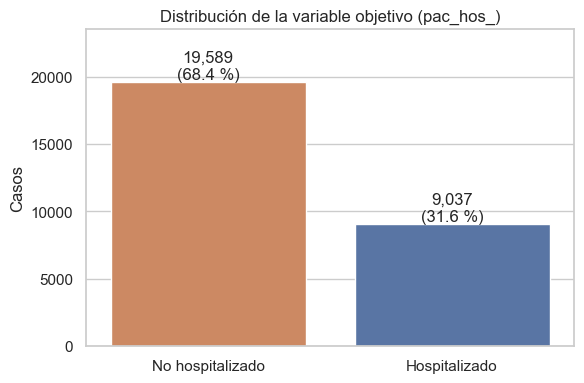

In [9]:
y_raw = df_raw["pac_hos_"].map({"1": "Hospitalizado", "2": "No hospitalizado"})
dist = y_raw.value_counts().to_frame("Casos")
dist["%"] = (100 * dist["Casos"] / dist["Casos"].sum()).round(2)
guardar_tabla(dist.reset_index().rename(columns={"pac_hos_": "Clase"}), "2_3_target")
print(dist)
print("Razón de desbalance (mayoritaria/minoritaria): %.2f : 1" % (dist["Casos"].max() / dist["Casos"].min()))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=y_raw, order=["No hospitalizado", "Hospitalizado"], ax=ax, hue=y_raw, legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({100*p.get_height()/len(y_raw):.1f} %)",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (pac_hos_)"); ax.set_xlabel(""); ax.set_ylabel("Casos")
ax.set_ylim(0, dist["Casos"].max() * 1.2)
guardar_fig("2_3_distribucion_target")

**Interpretación.** El problema está **moderadamente desbalanceado** (aproximadamente 2,17 : 1). No es un desbalance extremo, pero sí suficiente para que un clasificador ingenuo favorezca la clase mayoritaria y para que la *Accuracy* no sea una métrica adecuada. Esto justifica (i) usar **F1-macro** como métrica principal, (ii) particionar de forma **estratificada** y (iii) aplicar una técnica de **balanceo solo sobre los datos de entrenamiento** (sección 3.7).

### 2.4 Identificación de posibles sesgos

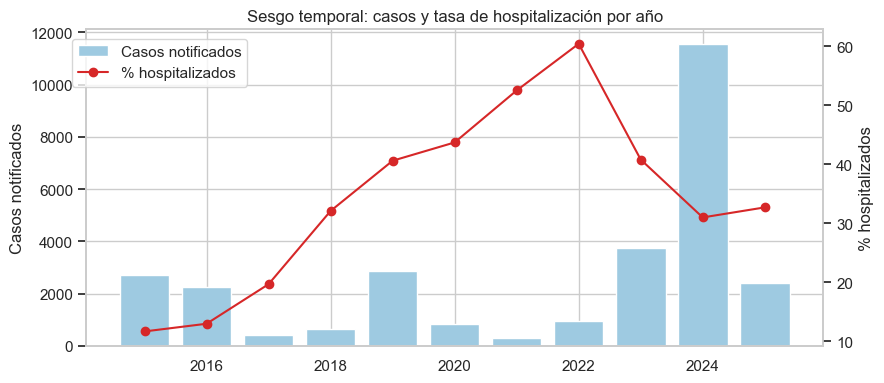

año,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
casos,2695.0,2234.0,411.0,655.0,2856.0,828.0,297.0,953.0,3738.0,11541.0,2418.0
tasa_hosp,11.7,13.0,19.7,32.1,40.6,43.7,52.5,60.4,40.8,31.0,32.7


In [10]:
tmp = df_raw.assign(y=(df_raw["pac_hos_"] == "1").astype(int), año=num(df_raw["año"]))
por_año = tmp.groupby("año").agg(casos=("y", "size"), tasa_hosp=("y", "mean"))
por_año["tasa_hosp"] = (100 * por_año["tasa_hosp"]).round(1)
guardar_tabla(por_año.reset_index(), "2_4_sesgo_temporal")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(por_año.index, por_año["casos"], color="#9ecae1", label="Casos notificados")
ax1.set_ylabel("Casos notificados")
ax2 = ax1.twinx()
ax2.plot(por_año.index, por_año["tasa_hosp"], color="#d62728", marker="o", label="% hospitalizados")
ax2.set_ylabel("% hospitalizados"); ax2.grid(False)
ax1.set_title("Sesgo temporal: casos y tasa de hospitalización por año")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.9))
guardar_fig("2_4_sesgo_temporal")
por_año.T

In [11]:
sesgos = []
sesgos.append(("Temporal / deriva", f"Tasa de hospitalización entre {por_año.tasa_hosp.min()} % y {por_año.tasa_hosp.max()} % según el año"))
sesgos.append(("Concentración en brote", f"El año 2024 aporta el {100*(tmp['año']==2024).mean():.1f} % de los registros"))
sesgos.append(("Geográfico", f"{100*(df_raw['cod_mun_r'].isin(['1','001'])&(df_raw['cod_dpto_r']=='68')).mean():.1f} % reside en Bucaramanga"))
for g, nombre in [("gp_migrant", "Migrantes"), ("gp_gestan", "Gestantes"), ("gp_indigen", "Indígenas")]:
    n = (df_raw[g] == "1").sum()
    sesgos.append(("Grupos minoritarios", f"{nombre}: {n} casos ({100*n/len(df_raw):.2f} %)"))
reg = tmp.assign(regimen=df_raw["tip_ss_"].str.upper().str.strip().map(REGIMEN)).groupby("regimen")["y"].agg(casos="size", tasa_hosp="mean").round(3)
sesgos.append(("Subregistro", "Solo casos notificados al SIVIGILA (los leves que no consultan no aparecen)"))
tabla_sesgos = guardar_tabla(pd.DataFrame(sesgos, columns=["Tipo de sesgo", "Evidencia"]), "2_4_sesgos")
display(tabla_sesgos)
guardar_tabla(reg.reset_index(), "2_4_sesgo_regimen")
print("Tasa de hospitalización por régimen (tip_ss_ normalizado):"); print(reg)

,Tipo de sesgo,Evidencia
0,Temporal / deriva,Tasa de hospitalización entre 11.7 % y 60.4 % ...
1,Concentración en brote,El año 2024 aporta el 40.3 % de los registros
2,Geográfico,96.3 % reside en Bucaramanga
3,Grupos minoritarios,Migrantes: 300 casos (1.05 %)
4,Grupos minoritarios,Gestantes: 183 casos (0.64 %)
5,Grupos minoritarios,Indígenas: 18 casos (0.06 %)
6,Subregistro,Solo casos notificados al SIVIGILA (los leves ...


Tasa de hospitalización por régimen (tip_ss_ normalizado):
         casos  tasa_hosp
regimen                  
C        19475      0.270
E          344      0.430
I          172      0.297
N          274      0.434
P          959      0.303
S         7402      0.429


**Interpretación de sesgos.**
- **Sesgo temporal (deriva del concepto):** la proporción de hospitalizados varía de forma drástica entre años (de aproximadamente 12 % en 2015 y 2016 a cerca de 60 % en 2022), lo que refleja cambios en protocolos clínicos, en la virulencia de los serotipos circulantes y en la forma de notificar. El modelo aprenderá principalmente el comportamiento reciente (2023 a 2025 suman el 62 % de los datos), por lo que **debe monitorearse y reentrenarse** periódicamente. No se usa `año` como predictor porque el objetivo no es pronosticar series de tiempo y porque amarraría el modelo a periodos pasados.
- **Sesgo de brote:** 2024 concentra el 40 % de los casos; el perfil de ese brote domina el aprendizaje.
- **Sesgo geográfico:** casi todos los casos son de Bucaramanga; el modelo **no debe generalizarse** a otras ciudades sin validación.
- **Grupos minoritarios** (migrantes, gestantes, indígenas) con muy pocos casos: el desempeño en esos subgrupos es incierto (riesgo de equidad).
- **Sesgo de selección / subregistro:** solo existen los casos que consultaron y fueron notificados.
- **Sesgo por régimen de afiliación:** la tasa de hospitalización difiere entre regímenes (contributivo, subsidiado, excepción), lo que puede reflejar acceso al servicio más que gravedad clínica.

---
# FASE 3. Preparación de los datos

### 3.1 Selección de variables
Criterios aplicados, en este orden:
1. **Eliminar fuga de información (*data leakage*)**: todo lo que se conoce *después* de decidir la hospitalización. Igual que en el caso de estudio del curso se eliminó la *Nota Final* para predecir *Aprobó*, aquí se eliminan `fec_hos_`, `conducta`, `clasfinal`, el evento final, la confirmación de laboratorio, el desenlace y las muestras de autopsia.
2. **Eliminar identificadores y variables administrativas** (`orden`, `version`, `fuente_`, `fec_not`).
3. **Eliminar variables casi constantes o de altísima cardinalidad** sin valor predictivo generalizable.
4. **Construir variables derivadas** con significado clínico: `edad_aprox` (punto medio del grupo etario), `dias_sintomas` (tiempo de evolución al consultar) y `mes` (estacionalidad).

Primero se **verifica empíricamente la fuga** de las variables más sospechosas:

In [12]:
print("fec_hos_ vacía (1900-01-01) vs target:")
print(pd.crosstab(df_raw["fec_hos_"].str.startswith("1900"), df_raw["pac_hos_"], margins=True))
cond = df_raw["conducta"].replace({"AMBULATORIA": "1", "HOSPITALIZACION PISO": "2", "UNIDAD DE CUIDADOS INTENSIVOS": "3"})
print("\nconducta (1=ambulatoria, 2=hosp. piso, 3=UCI) vs target:")
print(pd.crosstab(cond, df_raw["pac_hos_"]).loc[["1", "2", "3"]])

fec_hos_ vacía (1900-01-01) vs target:
pac_hos_     1      2    All
fec_hos_                    
False     9036      2   9038
True         1  19587  19588
All       9037  19589  28626

conducta (1=ambulatoria, 2=hosp. piso, 3=UCI) vs target:
pac_hos_     1      2
conducta             
1          120  15185
2         7792   3130
3          506     14


**Interpretación.** `fec_hos_` coincide con el target en el **99,99 %** de los casos y `conducta` es literalmente la decisión de hospitalizar: incluirlas daría un modelo "perfecto" en el notebook pero **inútil en la práctica**, porque esa información no existe en el momento de la consulta.

**Iteración CRISP-DM (de la Fase 3 a la Fase 1).** Los signos de *dengue grave* (`extravasac`, `hemorr_hem`, `choque`, `daño_organ`) generaron una discusión: son hallazgos clínicos, pero en la práctica se documentan casi siempre **durante la hospitalización**. Se realizó un experimento (abajo) que muestra cuánto "ayudan" al modelo; con base en él **se volvió a la Fase 1 para precisar el problema**: *predecir en la primera consulta*, con lo cual estos signos quedan excluidos.

In [13]:
# Experimento: ¿cuánto aportan los signos de dengue grave? (modelo rápido, solo para la decisión)
_b = lambda c: df_raw[c].map({"1": 1, "2": 0})
X_exp = pd.DataFrame({c: _b(c) for c in SINTOMAS}).fillna(0)
y_exp = (df_raw["pac_hos_"] == "1").astype(int)
cv_exp = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
f1_sin = cross_val_score(XGBClassifier(n_estimators=200, verbosity=0, n_jobs=N_JOBS), X_exp, y_exp, cv=cv_exp, scoring="f1_macro").mean()
X_exp2 = X_exp.join(pd.DataFrame({c: _b(c) for c in SIGNOS_GRAVE}).fillna(0))
f1_con = cross_val_score(XGBClassifier(n_estimators=200, verbosity=0, n_jobs=N_JOBS), X_exp2, y_exp, cv=cv_exp, scoring="f1_macro").mean()
print(f"F1-macro solo síntomas: {f1_sin:.4f} | con signos de dengue grave: {f1_con:.4f} | diferencia: {f1_con-f1_sin:+.4f}")

F1-macro solo síntomas: 0.8304 | con signos de dengue grave: 0.8302 | diferencia: -0.0001


**Interpretación de resultados: Experimento signos de dengue grave (iteración CRISP-DM).** Iteración CRISP-DM (de la Fase 3 a la Fase 1). Los signos de dengue grave (extravasación, hemorragia con compromiso hemodinámico, choque y daño de órganos) son hallazgos clínicos, pero en la práctica se documentan durante la hospitalización. Se hizo un experimento con XGBoost: el F1-macro fue 0,8304 sin estos signos y 0,8302 con ellos (diferencia de -0,0001). Es decir, no aportan capacidad predictiva adicional, porque están presentes en menos del 0,3 % de los casos. Con esta evidencia se volvió a la Fase 1 para precisar el alcance del problema: "predecir en la primera consulta". En consecuencia, estos signos se excluyen por coherencia con el momento de la decisión, sin pérdida de desempeño.

In [14]:
TARGET = "hospitalizado"
NUM_FEATS = ["edad_aprox", "dias_sintomas", "estrato", "mes"]
BIN_FEATS = SINTOMAS + OTRAS_BIN
CAT_FEATS = ["sexo", "regimen"]
FEATURES = NUM_FEATS + BIN_FEATS + CAT_FEATS

JUSTIF = {
    "edad_aprox": "Derivada de grupo_etario. Niños y adultos mayores tienen más riesgo de complicación",
    "dias_sintomas": "Derivada (consulta - inicio). La fase crítica del dengue ocurre entre los días 3 y 7",
    "estrato": "Proxy socioeconómico (acceso a servicios, condiciones de vivienda)",
    "mes": "Derivada de ini_sin_. Captura la estacionalidad de los brotes",
    "sexo": "Variable demográfica básica", "regimen": "Régimen de afiliación (tip_ss_ normalizado)",
    "desplazami": "Desplazamiento reciente (exposición)", "famantdngu": "Nexo epidemiológico familiar",
    "gp_gestan": "Gestantes: grupo de riesgo según guía clínica", "gp_migrant": "Migrantes: posible barrera de acceso",
}
for s in SINTOMAS[:6]: JUSTIF[s] = "Síntoma de dengue sin signos de alarma (guía clínica)"
for s in SINTOMAS[6:]: JUSTIF[s] = "Signo de alarma de dengue: criterio clínico de hospitalización"
seleccion = guardar_tabla(pd.DataFrame({"Variable seleccionada": FEATURES,
                                        "Justificación": [JUSTIF[f] for f in FEATURES]}), "3_1_seleccion")
print(f"Variables de entrada: {len(FEATURES)} ({len(NUM_FEATS)} numéricas, {len(BIN_FEATS)} binarias, {len(CAT_FEATS)} categóricas)")
seleccion

Variables de entrada: 27 (4 numéricas, 21 binarias, 2 categóricas)


,Variable seleccionada,Justificación
0,edad_aprox,Derivada de grupo_etario. Niños y adultos mayo...
1,dias_sintomas,Derivada (consulta - inicio). La fase crítica ...
2,estrato,"Proxy socioeconómico (acceso a servicios, cond..."
3,mes,Derivada de ini_sin_. Captura la estacionalida...
4,fiebre,Síntoma de dengue sin signos de alarma (guía c...
5,cefalea,Síntoma de dengue sin signos de alarma (guía c...
6,dolrretroo,Síntoma de dengue sin signos de alarma (guía c...
7,malgias,Síntoma de dengue sin signos de alarma (guía c...
8,artralgia,Síntoma de dengue sin signos de alarma (guía c...
9,erupcionr,Síntoma de dengue sin signos de alarma (guía c...


### 3.2 Descripción estadística y reporte ydata-profiling
Se construye el dataset con las variables seleccionadas **tal como vienen** (antes de limpiar), de modo que el reporte exploratorio evidencie los problemas de calidad que luego se corrigen. El reporte HTML se guarda en `reports/reporte_profiling.html` y se adjunta a la entrega.

In [15]:
df_sel = pd.DataFrame({
    "grupo_etario": df_raw["grupo_etario"], "dias_sintomas": _dias,
    "estrato": df_raw["estrato_"], "mes": parse_fecha(df_raw["ini_sin_"]).dt.month,
    **{c: df_raw[c] for c in BIN_FEATS},
    "sexo": df_raw["sexo_"], "regimen": df_raw["tip_ss_"], "pac_hos_": df_raw["pac_hos_"],
})
desc = pd.DataFrame({"Métrica": ["Número de registros", "Número de variables (dataset original)",
                                 "Número de variables de entrada seleccionadas", "Variables numéricas",
                                 "Variables categóricas (21 binarias + 2 nominales)", "Variable objetivo",
                                 "Registros duplicados exactos en la fuente"],
                     "Resultado": [len(df_raw), df_raw.shape[1], len(FEATURES), len(NUM_FEATS),
                                   len(BIN_FEATS) + len(CAT_FEATS), "1 (pac_hos_, renombrada como hospitalizado)",
                                   int(df_raw.drop(columns="orden").duplicated().sum())]})
guardar_tabla(desc, "3_2_descripcion")
display(desc)
df_sel.describe(include="all").T.head(30)

,Métrica,Resultado
0,Número de registros,28626
1,Número de variables (dataset original),76
2,Número de variables de entrada seleccionadas,27
3,Variables numéricas,4
4,Variables categóricas (21 binarias + 2 nominales),23
5,Variable objetivo,"1 (pac_hos_, renombrada como hospitalizado)"
6,Registros duplicados exactos en la fuente,10


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
grupo_etario,28626,22,20 a 29,3131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dias_sintomas,28626.0,NaN,NaN,NaN,3.785754,4.24963,0.0,2.0,3.0,5.0,341.0
estrato,28011,7,3,7960,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mes,28626.0,NaN,NaN,NaN,6.144484,3.067864,1.0,4.0,6.0,8.0,12.0
fiebre,28626,3,1,23900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cefalea,28626,4,1,20001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dolrretroo,28626,4,2,17844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
malgias,28626,3,1,20424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artralgia,28626,3,1,16468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
erupcionr,28626,4,2,20128,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
from ydata_profiling import ProfileReport
t0 = time.time()
profile = ProfileReport(df_sel, title="Dengue Bucaramanga: Reporte exploratorio (variables seleccionadas)",
                        explorative=True, progress_bar=False)
profile.config.interactions.continuous = False   # evita miles de gráficos de dispersión
profile.to_file("reports/reporte_profiling.html")
print(f"Reporte generado en {time.time()-t0:.0f} s -> reports/reporte_profiling.html")

Reporte generado en 10 s -> reports/reporte_profiling.html


**Interpretación del reporte.** El reporte ydata-profiling confirma las alertas detectadas con las reglas de calidad: valores `-89` en `estrato`, categorías duplicadas por mayúsculas en `grupo_etario` y `regimen`, valores `3` en las binarias y una distribución muy asimétrica de `dias_sintomas` (mediana 3 días con cola hasta 341). También muestra que varias binarias están muy desbalanceadas (p. ej. `hipotermia`, `hipotensio`), lo que es esperable en signos de alarma poco frecuentes.

### 3.3 Limpieza de errores
La limpieza de errores es **determinística** (reglas fijas que no "aprenden" de los datos), por eso puede aplicarse a todo el dataset antes de la partición sin generar fuga. Lo que sí aprende de los datos (imputación, escalado, codificación, SMOTE) se ajusta solo con entrenamiento dentro del *pipeline*.

In [17]:
EDAD_GRUPO = {"MENOR DE 1": 0.5, "1 A 4": 2.5, "5 A 9": 7, "10 A 14": 12, "15 A 19": 17,
              "20 A 29": 24.5, "30 A 39": 34.5, "40 A 49": 44.5, "50 A 59": 54.5,
              "60 A 69": 64.5, "70 Y MAS": 75}

registro_limpieza = []
def log(tipo, accion, n):
    registro_limpieza.append({"Tipo de error": tipo, "Acción realizada": accion, "Registros afectados": int(n)})

def limpiar(df_in):
    out = pd.DataFrame(index=df_in.index)
    # Edad: normalizar mayúsculas y mapear a punto medio
    ge = df_in["grupo_etario"].str.upper().str.strip()
    log("Categorías inconsistentes (mayúsculas/minúsculas) en grupo_etario",
        "Normalización a mayúsculas y conversión a edad_aprox (punto medio del grupo)",
        (df_in["grupo_etario"] != ge).sum())
    out["edad_aprox"] = ge.map(EDAD_GRUPO)
    # Fechas mixtas y días de síntomas
    fc, fi = parse_fecha(df_in["fec_con_"]), parse_fecha(df_in["ini_sin_"])
    log("Formatos de fecha mixtos (ISO y dd/mm/aaaa)", "Parseo con ambos formatos",
        df_in["fec_con_"].str.contains("/").sum())
    d = (fc - fi).dt.days
    fuera = (d < 0) | (d > 30)
    log("dias_sintomas fuera de la regla [0, 30]", "Se convierte en NaN (se imputa luego)", fuera.sum())
    out["dias_sintomas"] = d.where(~fuera)
    out["mes"] = fi.dt.month
    # Estrato
    e = pd.to_numeric(df_in["estrato_"], errors="coerce")
    log("Centinela -89 o vacío en estrato_", "Se convierte en NaN", (~e.between(1, 6)).sum())
    out["estrato"] = e.where(e.between(1, 6))
    # Binarias: 1 -> 1, 2 -> 0, resto (-89, 3, 4) -> NaN
    n_inv = 0
    for c in BIN_FEATS:
        n_inv += (~df_in[c].isin(["1", "2"])).sum()
        out[c] = df_in[c].map({"1": 1, "2": 0})
    log("Binarias con -89, 3 (desconocido) o 4 (fuera de dominio)",
        "Recodificación: 1 se mantiene como 1, 2 pasa a 0 y los valores inválidos pasan a NaN", n_inv)
    # Categóricas
    out["sexo"] = df_in["sexo_"].where(df_in["sexo_"].isin(["M", "F"]))
    reg = df_in["tip_ss_"].str.upper().str.strip()
    log("tip_ss_ mezcla códigos y nombres, con error de codificación (la palabra EXCEPCIÓN aparece con caracteres dañados)",
        "Mapeo a códigos oficiales C/S/P/E/N/I", (reg.str.len() > 1).sum())
    out["regimen"] = reg.map(REGIMEN)
    # Target
    out[TARGET] = df_in["pac_hos_"].map({"1": 1, "2": 0})
    return out

mask_dup = df_raw.drop(columns="orden").duplicated()
df = limpiar(df_raw.loc[~mask_dup])
log("Registros duplicados exactos (todas las columnas excepto el consecutivo 'orden')",
    "Se eliminan (misma notificación registrada dos veces)", mask_dup.sum())
tabla_limpieza = guardar_tabla(pd.DataFrame(registro_limpieza), "3_3_limpieza")
display(tabla_limpieza)
print("Dataset limpio:", df.shape); df.head()

,Tipo de error,Acción realizada,Registros afectados
0,Categorías inconsistentes (mayúsculas/minúscul...,Normalización a mayúsculas y conversión a edad...,18463
1,Formatos de fecha mixtos (ISO y dd/mm/aaaa),Parseo con ambos formatos,116
2,"dias_sintomas fuera de la regla [0, 30]",Se convierte en NaN (se imputa luego),73
3,Centinela -89 o vacío en estrato_,Se convierte en NaN,6478
4,"Binarias con -89, 3 (desconocido) o 4 (fuera d...","Recodificación: 1 se mantiene como 1, 2 pasa a...",6155
5,"tip_ss_ mezcla códigos y nombres, con error de...",Mapeo a códigos oficiales C/S/P/E/N/I,10153
6,Registros duplicados exactos (todas las column...,Se eliminan (misma notificación registrada dos...,10


Dataset limpio: (28616, 28)


,edad_aprox,dias_sintomas,mes,estrato,fiebre,cefalea,dolrretroo,malgias,artralgia,erupcionr,dolor_abdo,vomito,diarrea,somnolenci,hipotensio,hepatomeg,hem_mucosa,hipotermia,aum_hemato,caida_plaq,acum_liqui,desplazami,famantdngu,gp_gestan,gp_migrant,sexo,regimen,hospitalizado
0,12.0,0.0,1,NaN,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,1
1,17.0,2.0,1,NaN,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,0
2,24.5,1.0,1,NaN,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,F,C,0
3,64.5,3.0,1,NaN,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,0
4,34.5,1.0,1,NaN,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,0


**Interpretación.** Tras la limpieza todas las variables cumplen su regla de calidad: los valores que no cumplen se transformaron en **faltantes explícitos (NaN)** en lugar de eliminar registros, para no perder casos y dejar que el *pipeline* los impute de forma controlada.

### Partición 70 / 30 (estratificada)
Se separa el **30 % como conjunto de prueba** que no se toca hasta la Fase 5. Todo el ajuste (imputación, escalado, SMOTE, validación cruzada e hiperparámetros) se hace **solo con el 70 % de entrenamiento**.

In [18]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
particion = pd.DataFrame({"Conjunto": ["Entrenamiento (70 %)", "Prueba (30 %)"],
                          "Registros": [len(X_train), len(X_test)],
                          "% Hospitalizado": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)]})
guardar_tabla(particion, "3_particion"); particion

,Conjunto,Registros,% Hospitalizado
0,Entrenamiento (70 %),20031,31.58
1,Prueba (30 %),8585,31.58


### 3.4 Limpieza de valores nulos

In [19]:
nulos = pd.DataFrame({"% Nulos (total)": (100 * df[FEATURES].isna().mean()).round(2),
                      "% Nulos (entrenamiento)": (100 * X_train.isna().mean()).round(2)})
nulos["Método aplicado"] = np.where(nulos.index.isin(NUM_FEATS),
                                    "KNNImputer (k=5) dentro del pipeline",
                                    "SimpleImputer (moda) dentro del pipeline")
nulos = nulos[nulos["% Nulos (total)"] > 0].sort_values("% Nulos (total)", ascending=False)
guardar_tabla(nulos.reset_index().rename(columns={"index": "Variable"}), "3_4_nulos")
nulos

,% Nulos (total),% Nulos (entrenamiento),Método aplicado
estrato,22.64,22.50,KNNImputer (k=5) dentro del pipeline
famantdngu,19.35,19.21,SimpleImputer (moda) dentro del pipeline
gp_gestan,2.02,2.06,SimpleImputer (moda) dentro del pipeline
dias_sintomas,0.26,0.28,KNNImputer (k=5) dentro del pipeline
desplazami,0.03,0.03,SimpleImputer (moda) dentro del pipeline
cefalea,0.01,0.01,SimpleImputer (moda) dentro del pipeline
dolrretroo,0.01,0.01,SimpleImputer (moda) dentro del pipeline
diarrea,0.01,0.01,SimpleImputer (moda) dentro del pipeline
erupcionr,0.01,0.01,SimpleImputer (moda) dentro del pipeline
dolor_abdo,0.01,0.01,SimpleImputer (moda) dentro del pipeline


**Justificación de los métodos.**
- **Numéricas (`estrato`, `dias_sintomas`): `KNNImputer(n_neighbors=5)`**: estima el valor a partir de los 5 casos más parecidos en las demás numéricas (edad, mes, días), conservando relaciones entre variables mejor que la media. Es el mismo criterio aplicado en el caso de estudio del curso.
- **Binarias y categóricas: `SimpleImputer(strategy="most_frequent")`**: la moda es la imputación natural para variables nominales; los porcentajes faltantes son bajos, salvo `famantdngu` (~19 %), donde la moda ("No") es también la respuesta clínicamente más probable.
- Los imputadores se ajustan **solo con los datos de entrenamiento de cada partición** (están dentro del *pipeline*), con lo que se evita la fuga de información hacia la validación y el conjunto de prueba.

### 3.5 Codificación de variables categóricas y escalado

In [20]:
codif = pd.DataFrame([
    ("sexo", "OneHotEncoder(handle_unknown='ignore')", "Nominal sin orden"),
    ("regimen", "OneHotEncoder(handle_unknown='ignore')", "Nominal sin orden (6 categorías)"),
    ("17 síntomas/signos + 4 binarias", "Codificación binaria 1/0 (1 = Sí; el 2 original pasa a 0 = No)", "Dicotómicas: un solo indicador basta"),
    ("grupo_etario (convertida en edad_aprox)", "Codificación ordinal numérica (punto medio del rango)", "Conserva el orden y la magnitud de la edad"),
    ("estrato", "Ordinal numérica (1 a 6)", "El estrato tiene orden natural"),
    ("Numéricas (edad_aprox, dias_sintomas, estrato, mes)", "StandardScaler", "LR, SVM, KNN y MLP son sensibles a la escala"),
    ("hospitalizado (target)", "Codificación de etiquetas 1 = Hospitalizado, 0 = No", "La clase positiva es la de interés clínico"),
], columns=["Variable", "Método de codificación", "Justificación"])
guardar_tabla(codif, "3_5_codificacion"); codif

,Variable,Método de codificación,Justificación
0,sexo,OneHotEncoder(handle_unknown='ignore'),Nominal sin orden
1,regimen,OneHotEncoder(handle_unknown='ignore'),Nominal sin orden (6 categorías)
2,17 síntomas/signos + 4 binarias,Codificación binaria 1/0 (1 = Sí; el 2 origina...,Dicotómicas: un solo indicador basta
3,grupo_etario (convertida en edad_aprox),Codificación ordinal numérica (punto medio del...,Conserva el orden y la magnitud de la edad
4,estrato,Ordinal numérica (1 a 6),El estrato tiene orden natural
5,"Numéricas (edad_aprox, dias_sintomas, estrato,...",StandardScaler,"LR, SVM, KNN y MLP son sensibles a la escala"
6,hospitalizado (target),"Codificación de etiquetas 1 = Hospitalizado, 0...",La clase positiva es la de interés clínico


In [21]:
def crear_preprocesador():
    num = Pipeline([("imputer", KNNImputer(n_neighbors=5)), ("scaler", StandardScaler())])
    binp = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_FEATS), ("bin", binp, BIN_FEATS), ("cat", cat, CAT_FEATS)])

prep_demo = crear_preprocesador().fit(X_train)
Xtr_prep = pd.DataFrame(prep_demo.transform(X_train), columns=prep_demo.get_feature_names_out(), index=X_train.index)
print("Dimensión tras preprocesar:", Xtr_prep.shape)
Xtr_prep.head()

Dimensión tras preprocesar: (20031, 33)


,num__edad_aprox,num__dias_sintomas,num__estrato,num__mes,bin__fiebre,bin__cefalea,bin__dolrretroo,bin__malgias,bin__artralgia,bin__erupcionr,bin__dolor_abdo,bin__vomito,bin__diarrea,bin__somnolenci,bin__hipotensio,bin__hepatomeg,bin__hem_mucosa,bin__hipotermia,bin__aum_hemato,bin__caida_plaq,bin__acum_liqui,bin__desplazami,bin__famantdngu,bin__gp_gestan,bin__gp_migrant,cat__sexo_F,cat__sexo_M,cat__regimen_C,cat__regimen_E,cat__regimen_I,cat__regimen_N,cat__regimen_P,cat__regimen_S
1563,2.609776,0.592136,0.258811,-0.046021,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
18833,1.013909,-0.739622,1.599045,-0.371304,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
8235,2.609776,-1.183542,0.482183,1.255110,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
22075,1.537144,1.036056,-0.634678,0.279262,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
22930,-0.686605,-0.739622,-1.751539,0.279262,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


**Interpretación.** El preprocesamiento produce 33 columnas: 4 numéricas escaladas, 21 binarias y 8 indicadoras one-hot (2 de sexo + 6 de régimen). `handle_unknown="ignore"` garantiza que una categoría nueva en producción no rompa la aplicación (problema común de despliegue señalado en el material del curso).

### Relaciones lineales y no lineales
- **Lineal:** correlación de **Pearson**.
- **No lineal (monótona):** correlación de **Spearman**.
- **No lineal (general):** **Información mutua**, que detecta cualquier dependencia (no solo monótona) entre cada variable y el target.

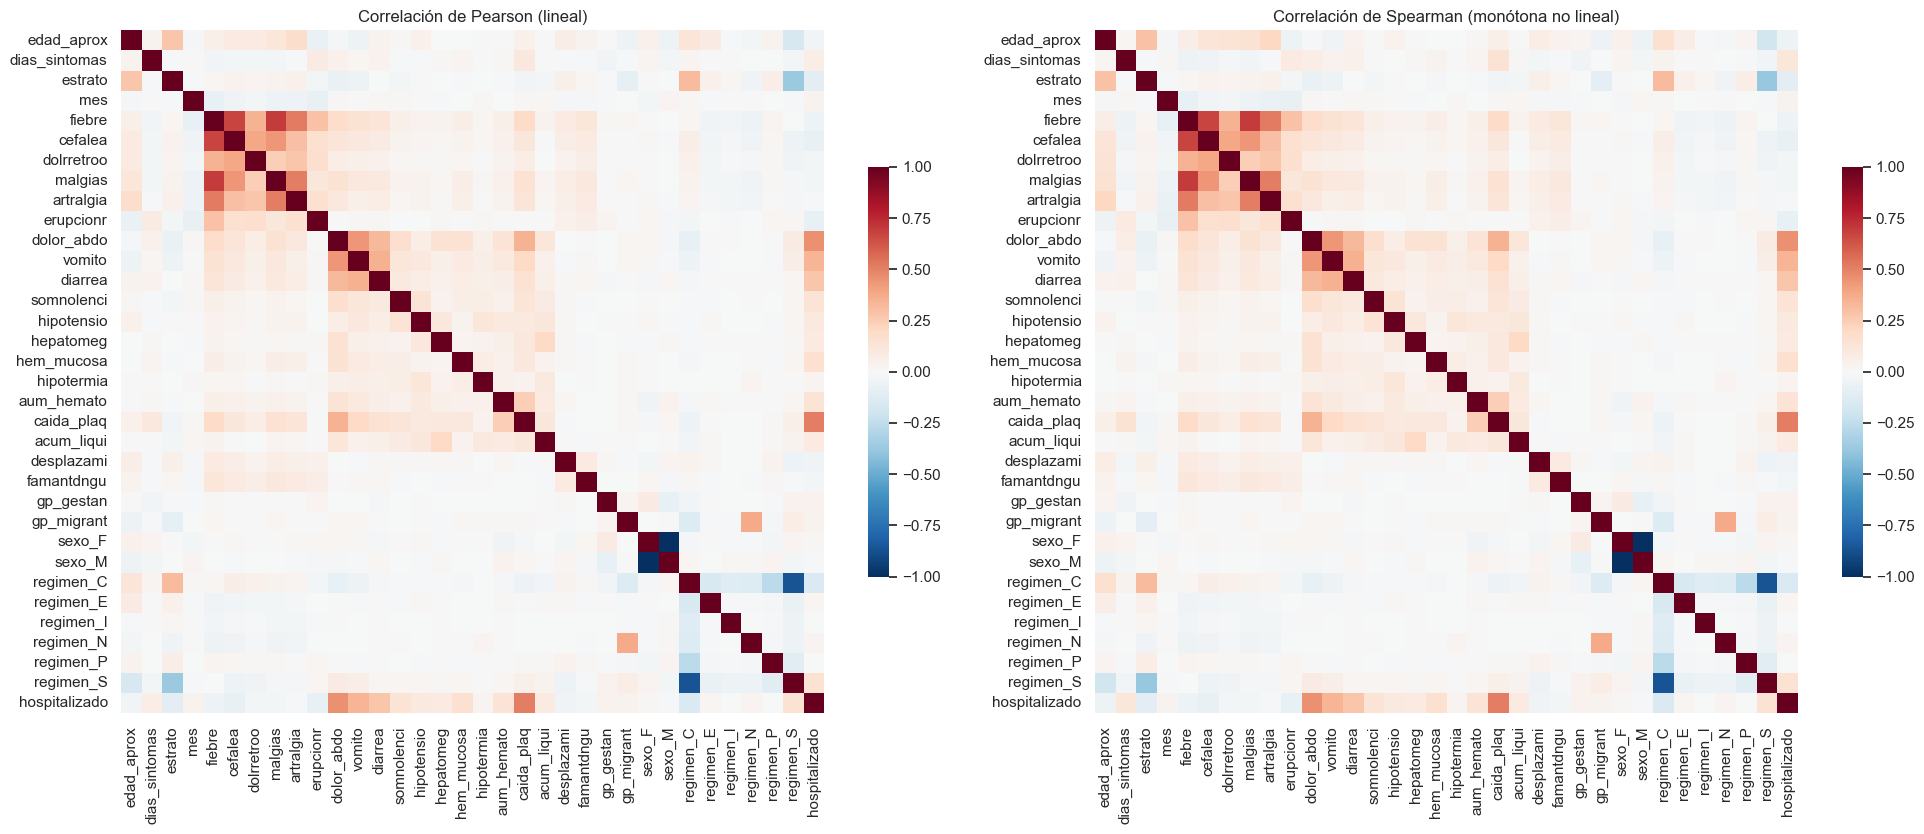

In [22]:
corr_df = Xtr_prep.copy(); corr_df[TARGET] = y_train.values
corr_df.columns = [c.split("__")[-1] for c in corr_df.columns]
pear = corr_df.corr(method="pearson"); spear = corr_df.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, m, t in [(axes[0], pear, "Pearson (lineal)"), (axes[1], spear, "Spearman (monótona no lineal)")]:
    sns.heatmap(m, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .6})
    ax.set_title(f"Correlación de {t}")
guardar_fig("3_6_correlaciones")

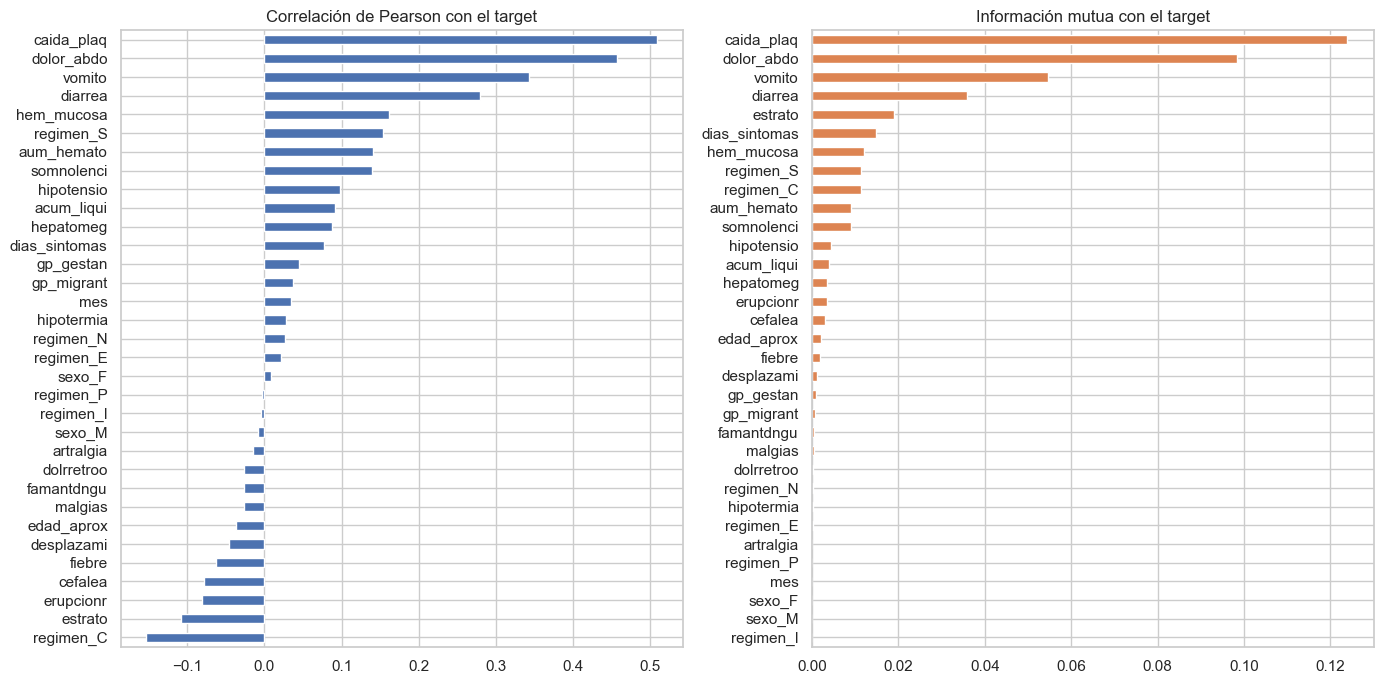

Pares de variables más correlacionados (Pearson):
sexo_F      sexo_M          -1.000
regimen_C   regimen_S       -0.862
fiebre      malgias          0.697
            cefalea          0.678
            artralgia        0.516
malgias     artralgia        0.510
caida_plaq  hospitalizado    0.509
dolor_abdo  hospitalizado    0.457
dtype: float64


,Pearson con target,Spearman con target,Información mutua
caida_plaq,0.5092,0.5092,0.1239
dolor_abdo,0.4568,0.4568,0.0983
vomito,0.3433,0.3433,0.0547
diarrea,0.2797,0.2797,0.0360
estrato,-0.1084,-0.1061,0.0189
dias_sintomas,0.0774,0.1209,0.0148
hem_mucosa,0.1611,0.1611,0.0120
regimen_S,0.1534,0.1534,0.0114
regimen_C,-0.1528,-0.1528,0.0114
aum_hemato,0.1405,0.1405,0.0091


In [23]:
mi = mutual_info_classif(Xtr_prep, y_train, discrete_features=[not c.startswith("num__") for c in Xtr_prep.columns],
                         random_state=RANDOM_STATE)
rel = pd.DataFrame({"Pearson con target": pear[TARGET].drop(TARGET),
                    "Spearman con target": spear[TARGET].drop(TARGET),
                    "Información mutua": pd.Series(mi, index=pear.columns.drop(TARGET))}).round(4)
rel = rel.sort_values("Información mutua", ascending=False)
guardar_tabla(rel.reset_index().rename(columns={"index": "Variable"}), "3_6_relaciones")
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
rel["Pearson con target"].sort_values().plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Correlación de Pearson con el target")
rel["Información mutua"].sort_values().plot.barh(ax=ax[1], color="#dd8452"); ax[1].set_title("Información mutua con el target")
guardar_fig("3_6_relacion_target")
pares = pear.where(np.triu(np.ones(pear.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Pares de variables más correlacionados (Pearson):"); print(pares.head(8).round(3))
rel.head(12)

**Interpretación de resultados: Relaciones lineales y no lineales.** Las variables con mayor relación con la hospitalización son signos de alarma: caída de plaquetas (Pearson r = 0,51; información mutua = 0,124), dolor abdominal (r = 0,46; IM = 0,098), vómito (r = 0,35) y diarrea (r = 0,28), en coherencia con la guía clínica del Ministerio de Salud. dias_sintomas tiene una relación lineal débil (Pearson 0,08), pero mayor en Spearman (0,12) y en información mutua: es una relación no lineal, porque el riesgo es mayor al consultar el día 0 y entre los días 4 y 6 (fase crítica) que en los días 1 y 2. El estrato tiene una relación inversa (r = -0,11): a menor estrato, mayor hospitalización. Entre predictores, las correlaciones más altas son las de los síntomas leves (fiebre con mialgias, 0,70) y las de las dummies de régimen (contributivo con subsidiado, -0,86, lo que es esperable). No hay multicolinealidad severa que obligue a eliminar variables. Como existen relaciones no lineales, se justifica incluir modelos no lineales (árboles, SVM con kernel RBF, MLP y ensambles).

### 3.6 Reducción de dimensiones
Se evalúa **PCA** sobre los datos preprocesados: cuántos componentes se requieren para retener el 90 % / 95 % de la varianza y si mejora el desempeño de un modelo base (Regresión Logística) en validación cruzada.

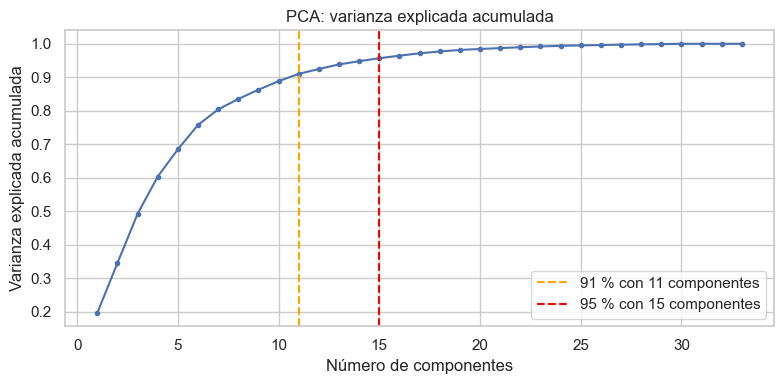

,Configuración,F1-macro CV (media),F1-macro CV (desv. est.)
0,Sin PCA (33 variables),0.8175,0.0031
1,Con PCA 95 % (15 componentes),0.8183,0.0015


In [24]:
pca = PCA(random_state=RANDOM_STATE).fit(Xtr_prep)
var_acum = np.cumsum(pca.explained_variance_ratio_)
k90, k95 = int(np.argmax(var_acum >= .90) + 1), int(np.argmax(var_acum >= .95) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(var_acum) + 1), var_acum, marker="o", ms=3)
for k, c in [(k90, "orange"), (k95, "red")]:
    ax.axvline(k, ls="--", color=c, label=f"{int(var_acum[k-1]*100)} % con {k} componentes")
ax.set_xlabel("Número de componentes"); ax.set_ylabel("Varianza explicada acumulada"); ax.legend()
ax.set_title("PCA: varianza explicada acumulada")
guardar_fig("3_7_pca")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_lr = LogisticRegression(max_iter=2000)
f1_sin_pca = cross_val_score(ImbPipeline([("prep", crear_preprocesador()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", base_lr)]),
                             X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=N_JOBS)
f1_con_pca = cross_val_score(ImbPipeline([("prep", crear_preprocesador()), ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                                          ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", base_lr)]),
                             X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=N_JOBS)
pca_res = pd.DataFrame({"Configuración": ["Sin PCA (33 variables)", f"Con PCA 95 % ({k95} componentes)"],
                        "F1-macro CV (media)": [f1_sin_pca.mean(), f1_con_pca.mean()],
                        "F1-macro CV (desv. est.)": [f1_sin_pca.std(), f1_con_pca.std()]}).round(4)
guardar_tabla(pca_res, "3_7_pca_resultado"); pca_res

**Interpretación de resultados: Reducción de dimensiones.** Para retener el 95 % de la varianza, PCA necesita 15 de los 33 componentes. Sin embargo, en validación cruzada con Regresión Logística el F1-macro fue prácticamente igual: 0,8175 +/- 0,0031 sin PCA y 0,8183 +/- 0,0015 con PCA (diferencia de +0,0008, menor que la desviación estándar). Como la reducción no mejora el desempeño de forma relevante, hace perder la interpretabilidad clínica de cada síntoma (necesaria para explicar el modelo al personal de salud y en la app) y no favorece a los modelos de árboles, se decide NO aplicarla. Con 33 variables y 20.031 registros de entrenamiento no hay riesgo de maldición de la dimensionalidad.

### 3.7 Balanceo de clases
Se comparan en validación cruzada (Regresión Logística como modelo de referencia) cuatro estrategias. **El balanceo se aplica dentro del pipeline de `imblearn`**, de modo que solo se remuestrea cada partición de entrenamiento: **las particiones de validación y el conjunto de prueba conservan la distribución real** (balancear el conjunto de prueba daría métricas irreales).

In [25]:
estrategias = {
    "Sin balanceo": ImbPipeline([("prep", crear_preprocesador()), ("model", LogisticRegression(max_iter=2000))]),
    "class_weight='balanced'": ImbPipeline([("prep", crear_preprocesador()), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE (sobremuestreo sintético)": ImbPipeline([("prep", crear_preprocesador()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", LogisticRegression(max_iter=2000))]),
    "RandomUnderSampler (submuestreo)": ImbPipeline([("prep", crear_preprocesador()), ("rus", RandomUnderSampler(random_state=RANDOM_STATE)), ("model", LogisticRegression(max_iter=2000))]),
}
filas = []
for nombre, pipe in estrategias.items():
    r = cross_validate(pipe, X_train, y_train, cv=skf, n_jobs=N_JOBS,
                       scoring={"f1_macro": "f1_macro", "recall_hosp": "recall", "precision_hosp": "precision"})
    filas.append({"Técnica": nombre, "F1-macro": r["test_f1_macro"].mean(),
                  "Recall (Hospitalizado)": r["test_recall_hosp"].mean(),
                  "Precision (Hospitalizado)": r["test_precision_hosp"].mean()})
balanceo = guardar_tabla(pd.DataFrame(filas).round(4), "3_8_balanceo"); balanceo

,Técnica,F1-macro,Recall (Hospitalizado),Precision (Hospitalizado)
0,Sin balanceo,0.8081,0.6668,0.8000
1,class_weight='balanced',0.8197,0.8517,0.6961
2,SMOTE (sobremuestreo sintético),0.8175,0.8512,0.6924
3,RandomUnderSampler (submuestreo),0.8186,0.8582,0.6914


**Decisión.** Se adopta **SMOTE dentro del pipeline** para todos los modelos. Aunque `class_weight` produce un efecto similar en la Regresión Logística, **no está disponible en KNN ni en MLP**, por lo que SMOTE permite tratar a los 10 modelos de forma homogénea y comparable. SMOTE genera ejemplos sintéticos de la clase minoritaria interpolando vecinos, en lugar de duplicar registros (sobreajuste) o descartar datos (pérdida de información, como el submuestreo).

---
# FASE 4. Modelamiento

Todos los modelos usan **exactamente el mismo pipeline** (`preprocesador, luego SMOTE, luego modelo`) y **las mismas 5 particiones** de validación cruzada estratificada (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`) **sobre el 70 % de entrenamiento**. Así las diferencias de desempeño se deben solo al algoritmo, y los puntajes por partición son **pareados**, lo que permite pruebas estadísticas en la Fase 5.

### 4.1 Modelos clásicos (modelos vistos en el curso)

In [26]:
def crear_pipeline(modelo):
    return ImbPipeline([("prep", crear_preprocesador()), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", modelo)])

SCORING = {"f1_macro": "f1_macro", "accuracy": "accuracy", "recall_hosp": "recall", "roc_auc": "roc_auc"}

clasicos = {
    "Regresión Logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
    "Red Neuronal (MLP)": MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
}
HIP_INI = {"Regresión Logística": "C=1.0, penalty='l2', solver='lbfgs'", "KNN": "n_neighbors=5, weights='uniform', p=2",
           "Árbol de Decisión": "max_depth=None, min_samples_leaf=1, criterion='gini'", "SVM": "kernel='rbf', C=1.0, gamma='scale'",
           "Red Neuronal (MLP)": "hidden_layer_sizes=(100,), activation='relu', alpha=0.0001, early_stopping=True"}

cv_scores = {}   # puntajes F1 por partición (para pruebas estadísticas)
def evaluar_cv(nombre, modelo):
    t0 = time.time()
    r = cross_validate(crear_pipeline(modelo), X_train, y_train, cv=skf, scoring=SCORING, n_jobs=N_JOBS, return_train_score=True)
    cv_scores[nombre] = r["test_f1_macro"]
    return {"Modelo": nombre, "CV Mean (F1-macro)": r["test_f1_macro"].mean(), "CV Std": r["test_f1_macro"].std(),
            "F1 entrenamiento": r["train_f1_macro"].mean(), "Recall Hosp.": r["test_recall_hosp"].mean(),
            "ROC-AUC": r["test_roc_auc"].mean(), "Tiempo (s)": time.time() - t0}

res_clasicos = pd.DataFrame([evaluar_cv(n, m) for n, m in clasicos.items()])
res_clasicos.insert(1, "Hiperparámetros iniciales", res_clasicos["Modelo"].map(HIP_INI))
res_clasicos.insert(2, "Métrica", "F1-macro")
res_clasicos = res_clasicos.round(4).sort_values("CV Mean (F1-macro)", ascending=False)
guardar_tabla(res_clasicos, "4_1_clasicos"); res_clasicos

,Modelo,Hiperparámetros iniciales,Métrica,CV Mean (F1-macro),CV Std,F1 entrenamiento,Recall Hosp.,ROC-AUC,Tiempo (s)
4,Red Neuronal (MLP),"hidden_layer_sizes=(100,), activation='relu', ...",F1-macro,0.8426,0.0044,0.8508,0.8776,0.9246,19.3654
3,SVM,"kernel='rbf', C=1.0, gamma='scale'",F1-macro,0.8314,0.0039,0.8420,0.8851,0.9102,63.3479
0,Regresión Logística,"C=1.0, penalty='l2', solver='lbfgs'",F1-macro,0.8175,0.0031,0.8185,0.8512,0.9077,22.7619
2,Árbol de Decisión,"max_depth=None, min_samples_leaf=1, criterion=...",F1-macro,0.7789,0.0062,0.9873,0.6979,0.7836,16.4827
1,KNN,"n_neighbors=5, weights='uniform', p=2",F1-macro,0.7730,0.0040,0.8710,0.7085,0.8462,19.7338


**Interpretación de resultados: Modelos clásicos.** La Red Neuronal (MLP) obtuvo el mejor desempeño inicial (F1-macro CV de 0,8426), seguida por SVM (0,8314) y Regresión Logística (0,8175). KNN (0,7730) y el Árbol de Decisión sin restricciones (0,7789) quedaron muy por debajo, y el árbol muestra un sobreajuste severo: F1 de 0,987 en entrenamiento frente a 0,779 en validación. Las desviaciones estándar son bajas (menor o igual a 0,0062), lo que indica estimaciones estables entre particiones. La ventaja de los modelos no lineales (MLP y SVM) sobre la regresión logística confirma las relaciones no lineales detectadas en la Fase 3.

### 4.2 Modelos de ensamble (actividad investigativa)

| Ensamble | Idea | Qué reduce |
|---|---|---|
| **Votación (Voting, suave)** | Combina modelos **distintos** promediando sus probabilidades. Funciona mejor cuando los modelos cometen errores diferentes (diversidad). | Varianza y error de modelo individual |
| **Bagging** (*Bootstrap Aggregating*, Breiman 1996) | Entrena muchos árboles sobre **muestras bootstrap** (con reemplazo) y vota. Promediar modelos inestables reduce su variabilidad. | **Varianza** |
| **Random Forest** (Breiman 2001) | Bagging + selección aleatoria de variables en cada división, lo que **descorrelaciona** los árboles. | Varianza (más que bagging) |
| **Boosting con XGBoost** (Chen & Guestrin 2016) | Entrena árboles **secuencialmente**; cada uno corrige los residuos (gradiente) del anterior, con regularización L1/L2. | **Sesgo** (y varianza por regularización) |

La **votación** usa los 3 mejores modelos clásicos según la validación cruzada inicial (por diversidad y desempeño).

In [27]:
top3 = res_clasicos["Modelo"].head(3).tolist()
def con_proba(nombre):
    m = clone(clasicos[nombre])
    if isinstance(m, SVC): m.set_params(probability=True)
    return m
print("Modelos de la votación:", top3)

ensambles = {
    "Votación (suave)": VotingClassifier([(n, con_proba(n)) for n in top3], voting="soft"),
    "Bagging (árboles)": BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "Boosting (XGBoost)": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, eval_metric="logloss",
                                        random_state=RANDOM_STATE, n_jobs=1, verbosity=0),
}
TIPO = {"Votación (suave)": "Votación", "Bagging (árboles)": "Bagging", "Random Forest": "Bagging", "Boosting (XGBoost)": "Boosting"}
res_ens = pd.DataFrame([evaluar_cv(n, m) for n, m in ensambles.items()])
mejor_clasico = res_clasicos.iloc[0]
res_ens.insert(1, "Tipo", res_ens["Modelo"].map(TIPO))
res_ens["Mejora vs mejor clásico (pts F1)"] = res_ens["CV Mean (F1-macro)"] - mejor_clasico["CV Mean (F1-macro)"]
res_ens["Mejora (%)"] = 100 * res_ens["Mejora vs mejor clásico (pts F1)"] / mejor_clasico["CV Mean (F1-macro)"]
res_ens = res_ens.round(4).sort_values("CV Mean (F1-macro)", ascending=False)
print(f"Mejor clásico: {mejor_clasico['Modelo']} (F1-macro CV = {mejor_clasico['CV Mean (F1-macro)']:.4f})")
guardar_tabla(res_ens, "4_2_ensambles"); res_ens

Modelos de la votación: ['Red Neuronal (MLP)', 'SVM', 'Regresión Logística']


Mejor clásico: Red Neuronal (MLP) (F1-macro CV = 0.8426)


,Modelo,Tipo,CV Mean (F1-macro),CV Std,F1 entrenamiento,Recall Hosp.,ROC-AUC,Tiempo (s),Mejora vs mejor clásico (pts F1),Mejora (%)
3,Boosting (XGBoost),Boosting,0.8435,0.0062,0.8943,0.7830,0.9259,18.7248,0.0009,0.1016
2,Random Forest,Bagging,0.8385,0.0042,0.9874,0.8084,0.9161,25.8136,-0.0041,-0.4840
0,Votación (suave),Votación,0.8369,0.0033,0.8453,0.8813,0.9217,140.2118,-0.0057,-0.6771
1,Bagging (árboles),Bagging,0.8328,0.0051,0.9873,0.7841,0.9110,27.7022,-0.0098,-1.1577


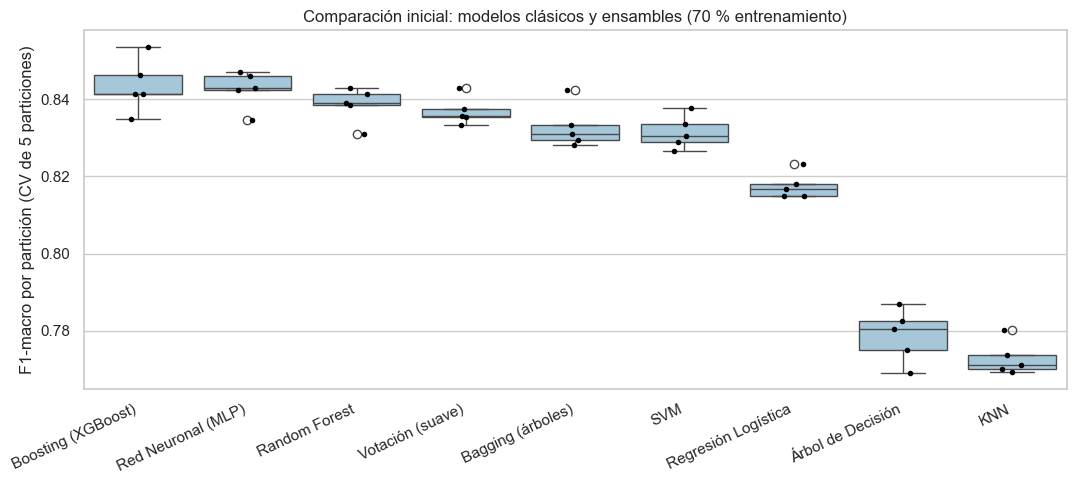

In [28]:
cv_ini = pd.DataFrame(cv_scores)
orden = cv_ini.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=cv_ini[orden], ax=ax, color="#9ecae1")
sns.stripplot(data=cv_ini[orden], ax=ax, color="black", size=4)
ax.set_ylabel("F1-macro por partición (CV de 5 particiones)"); ax.set_title("Comparación inicial: modelos clásicos y ensambles (70 % entrenamiento)")
plt.xticks(rotation=25, ha="right")
guardar_fig("4_comparacion_inicial")
cv_ini_guardado = cv_ini.copy()

**Interpretación de resultados: Ensambles.** En la comparación inicial, solo el Boosting (XGBoost) supera al mejor modelo clásico: F1-macro de 0,8435 frente a 0,8426 de la MLP (+0,0009). Random Forest (0,8385), Votación (0,8369) y Bagging (0,8328) quedan levemente por debajo con sus hiperparámetros por defecto, porque usan árboles completos que memorizan el entrenamiento (F1 entrenamiento de 0,987). La votación tiene la menor variabilidad entre particiones (desviación estándar 0,0033), que es el efecto esperado de promediar modelos diversos. El diagrama de caja muestra que las diferencias entre los mejores modelos son pequeñas en comparación con la dispersión entre particiones. Por eso hace falta ajustar los hiperparámetros y aplicar pruebas estadísticas antes de elegir.

### 4.3 Ajuste de hiperparámetros
- **Validación cruzada:** `GridSearchCV` (o `RandomizedSearchCV` cuando el espacio es grande) con las **mismas 5 particiones estratificadas sobre el 70 % de entrenamiento**.
- **Métrica de optimización:** `f1_macro`, coherente con el objetivo de negocio (equilibrar falsos positivos y falsos negativos con desbalance de clases).
- Se ajustan los **5 modelos clásicos y los 3 ensambles de árboles**; la votación se reconstruye con los modelos ya ajustados.
- Para cada hiperparámetro se reporta **qué controla, por qué se eligió el rango y cómo afectó el desempeño** (efecto marginal calculado a partir de `cv_results_`).

In [29]:
P = "model__"
espacios = {
    "Regresión Logística": (LogisticRegression(max_iter=3000, solver="liblinear", random_state=RANDOM_STATE),
        {P+"C": [0.001, 0.01, 0.1, 1, 10, 100], P+"penalty": ["l1", "l2"]}, "grid"),
    "KNN": (KNeighborsClassifier(),
        {P+"n_neighbors": [5, 15, 31, 51, 101], P+"weights": ["uniform", "distance"], P+"p": [1, 2]}, "grid"),
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE),
        {P+"max_depth": [3, 5, 8, 12, 20, None], P+"min_samples_leaf": [1, 10, 50, 100], P+"criterion": ["gini", "entropy"]}, "grid"),
    "SVM": (SVC(kernel="rbf", random_state=RANDOM_STATE),
        {P+"C": [0.1, 1, 10], P+"gamma": ["scale", 0.01, 0.1]}, "grid"),
    "Red Neuronal (MLP)": (MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
        {P+"hidden_layer_sizes": [(50,), (100,), (50, 50)], P+"alpha": [0.0001, 0.01, 0.1], P+"learning_rate_init": [0.001, 0.01]}, "grid"),
    "Bagging (árboles)": (BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE, n_jobs=1),
        {P+"n_estimators": [50, 150], P+"max_samples": [0.5, 0.8], P+"estimator__max_depth": [10, 20, None]}, "grid"),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {P+"n_estimators": [200], P+"max_depth": [12, 20, None], P+"min_samples_leaf": [1, 5, 20], P+"max_features": ["sqrt", 0.5]}, "grid"),
    "Boosting (XGBoost)": (XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1, verbosity=0),
        {P+"n_estimators": [100, 200, 400, 600], P+"learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
         P+"max_depth": [3, 4, 6, 8], P+"subsample": [0.7, 0.85, 1.0], P+"colsample_bytree": [0.6, 0.8, 1.0]}, "random"),
}

busquedas, tiempos = {}, {}
for nombre, (modelo, grid, tipo_b) in espacios.items():
    t0 = time.time()
    if tipo_b == "grid":
        gs = GridSearchCV(crear_pipeline(modelo), grid, cv=skf, scoring="f1_macro", n_jobs=N_JOBS, return_train_score=True)
    else:
        gs = RandomizedSearchCV(crear_pipeline(modelo), grid, n_iter=40, cv=skf, scoring="f1_macro", n_jobs=N_JOBS,
                                random_state=RANDOM_STATE, return_train_score=True)
    gs.fit(X_train, y_train)
    busquedas[nombre], tiempos[nombre] = gs, time.time() - t0
    print(f"{nombre:22s} mejor F1-macro CV = {gs.best_score_:.4f} | {time.time()-t0:6.0f} s | {gs.best_params_}")

Regresión Logística    mejor F1-macro CV = 0.8180 |    101 s | {'model__C': 0.01, 'model__penalty': 'l2'}


KNN                    mejor F1-macro CV = 0.7922 |    237 s | {'model__n_neighbors': 51, 'model__p': 1, 'model__weights': 'distance'}


Árbol de Decisión      mejor F1-macro CV = 0.8373 |    446 s | {'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 50}


SVM                    mejor F1-macro CV = 0.8325 |    401 s | {'model__C': 10, 'model__gamma': 0.1}


Red Neuronal (MLP)     mejor F1-macro CV = 0.8426 |    220 s | {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100,), 'model__learning_rate_init': 0.001}


Bagging (árboles)      mejor F1-macro CV = 0.8459 |    203 s | {'model__estimator__max_depth': 10, 'model__max_samples': 0.5, 'model__n_estimators': 150}


Random Forest          mejor F1-macro CV = 0.8465 |    277 s | {'model__max_depth': 12, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}


Boosting (XGBoost)     mejor F1-macro CV = 0.8492 |    471 s | {'model__subsample': 0.85, 'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}


In [30]:
# Votación reconstruida con los 3 mejores modelos ajustados (sus hiperparámetros óptimos)
top3_aj = sorted([n for n in clasicos], key=lambda n: busquedas[n].best_score_, reverse=True)[:3]
def modelo_ajustado(nombre, proba=False):
    m = clone(busquedas[nombre].best_estimator_.named_steps["model"])
    if proba and isinstance(m, SVC): m.set_params(probability=True)
    return m
voting_aj = VotingClassifier([(n, modelo_ajustado(n, proba=True)) for n in top3_aj], voting="soft")
r_vot = cross_validate(crear_pipeline(voting_aj), X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=N_JOBS)
print("Votación ajustada con:", top3_aj, "-> F1-macro CV = %.4f" % r_vot["test_score"].mean())

antes = {**dict(zip(res_clasicos["Modelo"], res_clasicos["CV Mean (F1-macro)"])),
         **dict(zip(res_ens["Modelo"], res_ens["CV Mean (F1-macro)"]))}
despues = {n: busquedas[n].best_score_ for n in busquedas}; despues["Votación (suave)"] = r_vot["test_score"].mean()
comp = pd.DataFrame({"F1-macro CV antes": antes, "F1-macro CV después": despues})
comp["Ganancia"] = comp["F1-macro CV después"] - comp["F1-macro CV antes"]
comp = comp.round(4).sort_values("F1-macro CV después", ascending=False)
guardar_tabla(comp.reset_index().rename(columns={"index": "Modelo"}), "4_3_antes_despues"); comp

Votación ajustada con: ['Red Neuronal (MLP)', 'Árbol de Decisión', 'SVM'] -> F1-macro CV = 0.8426


,F1-macro CV antes,F1-macro CV después,Ganancia
Boosting (XGBoost),0.8435,0.8492,0.0057
Random Forest,0.8385,0.8465,0.0080
Bagging (árboles),0.8328,0.8459,0.0131
Red Neuronal (MLP),0.8426,0.8426,0.0000
Votación (suave),0.8369,0.8426,0.0057
Árbol de Decisión,0.7789,0.8373,0.0584
SVM,0.8314,0.8325,0.0011
Regresión Logística,0.8175,0.8180,0.0005
KNN,0.7730,0.7922,0.0192


**Interpretación de resultados: Ajuste de hiperparámetros.** El ajuste mejoró a todos los modelos. Las mayores ganancias fueron para el Árbol de Decisión (+0,058, al limitar max_depth a 8 y exigir al menos 50 casos por hoja), KNN (+0,019, con 51 vecinos ponderados por distancia y distancia Manhattan) y Bagging (+0,013, con árboles de profundidad 10 y muestras del 50 %). El hiperparámetro más influyente fue max_depth del árbol (0,049 puntos de F1 entre el peor y el mejor valor): las curvas de validación muestran que sin límite de profundidad el F1 de entrenamiento se acerca a 1 mientras el de validación cae, lo que es sobreajuste. En los ensambles el efecto es menor (0,001 a 0,005), porque el promedio de muchos árboles ya controla la varianza. En XGBoost, la tasa de aprendizaje (0,03) y la profundidad (8) son los parámetros más relevantes. En la Regresión Logística, una regularización más fuerte (C = 0,01) dio un resultado ligeramente mejor que C = 1. Tras el ajuste, los tres ensambles de árboles superan a todos los modelos clásicos: XGBoost 0,8492, Random Forest 0,8465 y Bagging 0,8459.

In [31]:
QUE_CONTROLA = {
    "C": "Inverso de la regularización: C pequeño = modelo más simple (más sesgo); C grande = se ajusta más a los datos (más varianza)",
    "penalty": "Tipo de regularización: L1 (lasso) anula coeficientes y selecciona variables; L2 (ridge) los encoge suavemente",
    "n_neighbors": "Número de vecinos que votan: pocos = frontera irregular (sobreajuste); muchos = frontera suave (subajuste)",
    "weights": "Peso del voto: 'uniform' igual para todos; 'distance' los vecinos más cercanos pesan más",
    "p": "Métrica de distancia de Minkowski: p=1 Manhattan, p=2 Euclidiana",
    "max_depth": "Profundidad máxima del árbol: controla la complejidad y el sobreajuste",
    "min_samples_leaf": "Mínimo de casos por hoja: valores altos suavizan el modelo y evitan reglas basadas en pocos casos",
    "criterion": "Medida de impureza para escoger divisiones: Gini o entropía (ganancia de información)",
    "gamma": "Alcance del kernel RBF: gamma alto = cada punto influye poco (frontera muy flexible); bajo = frontera suave",
    "hidden_layer_sizes": "Arquitectura: número de capas ocultas y neuronas (capacidad del modelo)",
    "alpha": "Regularización L2 de los pesos de la red (evita sobreajuste)",
    "learning_rate_init": "Tamaño del paso inicial del optimizador Adam",
    "n_estimators": "Número de modelos (árboles) del ensamble",
    "max_samples": "Fracción de la muestra bootstrap usada por cada árbol (diversidad)",
    "estimator__max_depth": "Profundidad de cada árbol base del bagging",
    "max_features": "Variables candidatas en cada división (descorrelaciona los árboles)",
    "learning_rate": "Contribución de cada árbol nuevo (contracción): bajo = aprendizaje lento y más robusto",
    "subsample": "Fracción de registros usada por cada árbol (regulariza, reduce varianza)",
    "colsample_bytree": "Fracción de variables usada por cada árbol",
}
POR_QUE_RANGO = {
    "C": "Escala logarítmica de 1e-3 a 1e2: cubre desde regularización muy fuerte hasta casi nula",
    "penalty": "Las dos regularizaciones soportadas por liblinear (como en el caso de estudio del curso)",
    "n_neighbors": "De 5 (local) a 101 (aproximadamente raíz de n); valores impares para evitar empates",
    "weights": "Las dos opciones disponibles", "p": "Las dos distancias más usadas",
    "max_depth": "Desde árboles poco profundos e interpretables (3) hasta sin límite (None)",
    "min_samples_leaf": "De 1 (sin restricción) a 100 (aproximadamente 0,5 % del entrenamiento)",
    "criterion": "Los dos criterios clásicos",
    "gamma": "'scale' (1/(n_var*var)) y valores en escala logarítmica alrededor de él",
    "hidden_layer_sizes": "Una capa pequeña/mediana y dos capas: el problema tiene solo 33 entradas",
    "alpha": "Escala logarítmica de regularización débil a fuerte",
    "learning_rate_init": "Valor por defecto de Adam y uno 10 veces mayor",
    "n_estimators": "Rango típico (50 a 600); a partir de cierto número de árboles el error se estabiliza",
    "max_samples": "Mitad de la muestra (más diversidad entre árboles) vs 80 %",
    "estimator__max_depth": "Árboles medianos a completos (bagging funciona mejor con árboles de alta varianza)",
    "max_features": "Recomendación clásica (raíz) y la mitad de las variables",
    "learning_rate": "Rango recomendado para boosting (0.01 a 0.2)",
    "subsample": "Valores habituales de submuestreo estocástico",
    "colsample_bytree": "Valores habituales de submuestreo de columnas",
}

def efecto_hiperparametros(nombre, gs):
    cvr = pd.DataFrame(gs.cv_results_)
    filas = []
    for param in [k for k in cvr.columns if k.startswith("param_")]:
        hp = param.replace("param_model__", "")
        marg = cvr.groupby(cvr[param].astype(str))["mean_test_score"].max()
        mejor = str(gs.best_params_[param.replace("param_", "")])
        filas.append({"Modelo": nombre, "Hiperparámetro": hp, "Qué controla": QUE_CONTROLA.get(hp, ""),
                      "Rango probado": ", ".join(marg.index), "Por qué el rango": POR_QUE_RANGO.get(hp, ""),
                      "Valor final": mejor,
                      "F1 con peor valor": round(marg.min(), 4), "F1 con mejor valor": round(marg.max(), 4),
                      "Efecto (pts F1)": round(marg.max() - marg.min(), 4)})
    return filas

tabla_hp = pd.DataFrame([f for n, gs in busquedas.items() for f in efecto_hiperparametros(n, gs)])
guardar_tabla(tabla_hp, "4_3_hiperparametros")
tabla_hp[["Modelo", "Hiperparámetro", "Rango probado", "Valor final", "F1 con peor valor", "F1 con mejor valor", "Efecto (pts F1)"]]

,Modelo,Hiperparámetro,Rango probado,Valor final,F1 con peor valor,F1 con mejor valor,Efecto (pts F1)
0,Regresión Logística,C,"0.001, 0.01, 0.1, 1.0, 10.0, 100.0",0.01,0.8107,0.8180,0.0073
1,Regresión Logística,penalty,"l1, l2",l2,0.8175,0.8180,0.0005
2,KNN,n_neighbors,"101, 15, 31, 5, 51",51,0.7767,0.7922,0.0156
3,KNN,p,"1, 2",1,0.7919,0.7922,0.0003
4,KNN,weights,"distance, uniform",distance,0.7911,0.7922,0.0012
5,Árbol de Decisión,criterion,"entropy, gini",gini,0.8368,0.8373,0.0005
6,Árbol de Decisión,max_depth,"12, 20, 3, 5, 8, None",8,0.7882,0.8373,0.0491
7,Árbol de Decisión,min_samples_leaf,"1, 10, 100, 50",50,0.8330,0.8373,0.0042
8,SVM,C,"0.1, 1.0, 10.0",10,0.8224,0.8325,0.0101
9,SVM,gamma,"0.01, 0.1, scale",0.1,0.8207,0.8325,0.0118


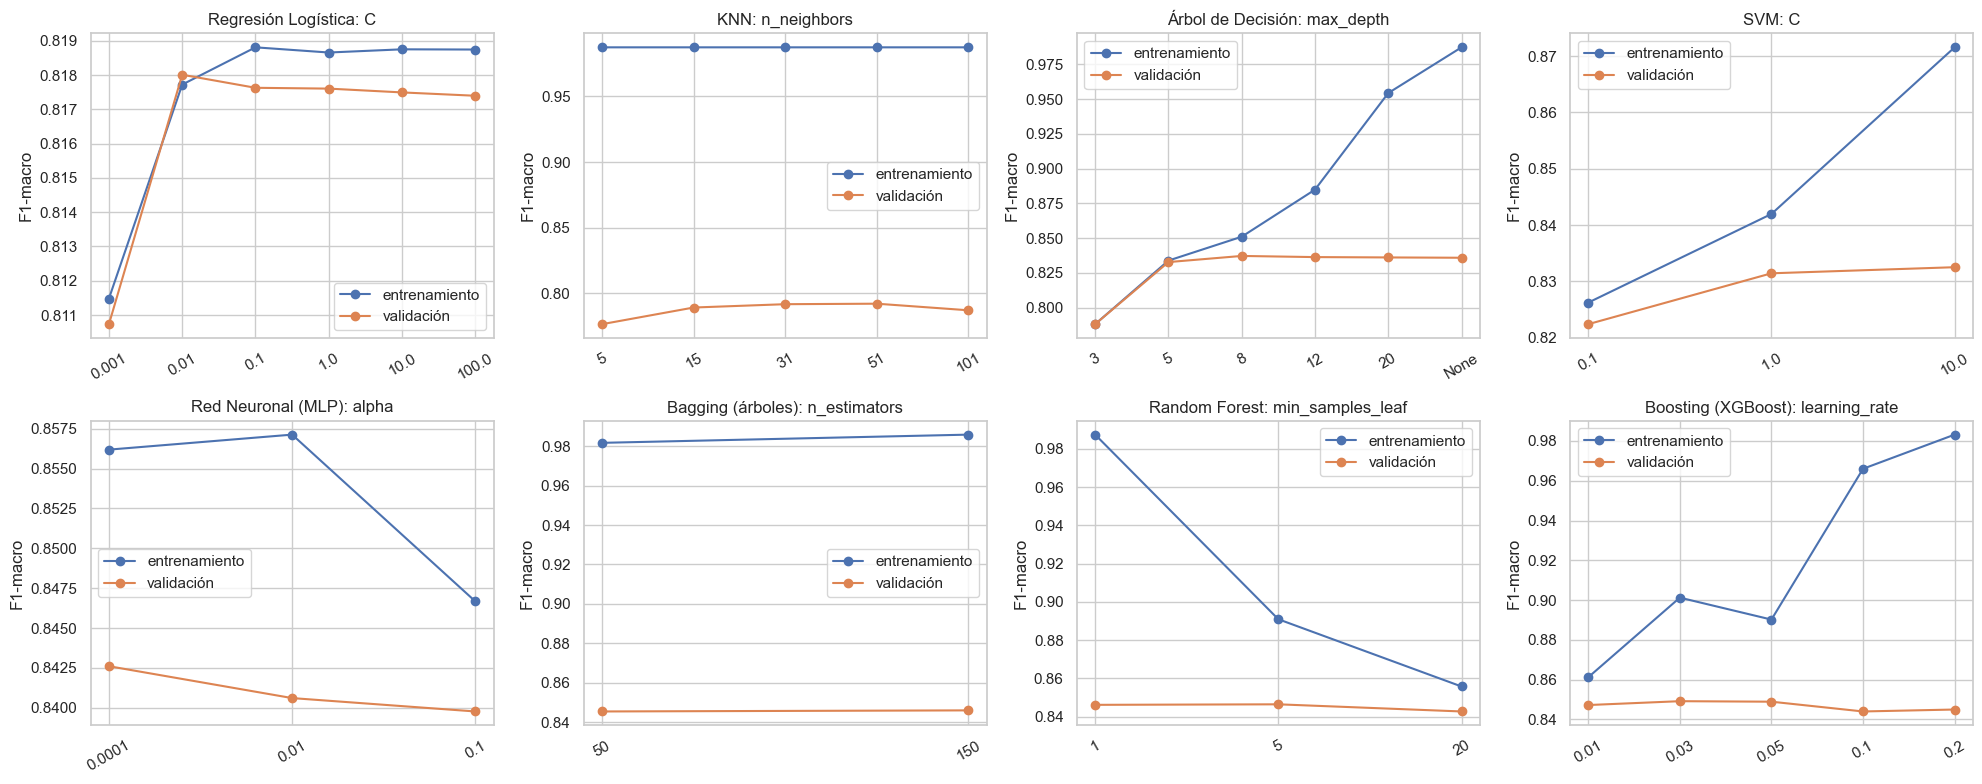

In [32]:
# Curvas de validación: efecto marginal del hiperparámetro principal de cada modelo
principales = {"Regresión Logística": "C", "KNN": "n_neighbors", "Árbol de Decisión": "max_depth", "SVM": "C",
               "Red Neuronal (MLP)": "alpha", "Bagging (árboles)": "n_estimators", "Random Forest": "min_samples_leaf",
               "Boosting (XGBoost)": "learning_rate"}
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, (nombre, hp) in zip(axes.ravel(), principales.items()):
    cvr = pd.DataFrame(busquedas[nombre].cv_results_)
    col = f"param_model__{hp}"
    g = cvr.groupby(cvr[col].astype(str)).agg(test=("mean_test_score", "max"), train=("mean_train_score", "max"))
    try: g = g.loc[sorted(g.index, key=lambda v: float(v) if v not in ("None",) else 1e9)]
    except ValueError: pass
    ax.plot(g.index, g["train"], marker="o", label="entrenamiento"); ax.plot(g.index, g["test"], marker="o", label="validación")
    ax.set_title(f"{nombre}: {hp}"); ax.set_ylabel("F1-macro"); ax.tick_params(axis="x", rotation=30); ax.legend()
guardar_fig("4_3_curvas_validacion")

---
# FASE 5. Evaluación

### 5.1 Resultados en el conjunto de prueba (30 %, nunca visto)
Se evalúan **todos los modelos ajustados**. Precision, Recall y F1 se reportan en promedio **macro** (coherente con la métrica de optimización) y adicionalmente para la clase de interés (*Hospitalizado*).

In [33]:
finales = {n: busquedas[n].best_estimator_ for n in busquedas}
finales["Votación (suave)"] = crear_pipeline(voting_aj).fit(X_train, y_train)

filas, preds, probas = [], {}, {}
for nombre, pipe in finales.items():
    yp = pipe.predict(X_test); preds[nombre] = yp
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") and not isinstance(pipe.named_steps["model"], SVC) \
        else pipe.decision_function(X_test)
    probas[nombre] = score
    yp_tr = pipe.predict(X_train)
    filas.append({"Modelo": nombre, "Accuracy": accuracy_score(y_test, yp),
                  "Precision": precision_score(y_test, yp, average="macro"),
                  "Recall": recall_score(y_test, yp, average="macro"),
                  "F1": f1_score(y_test, yp, average="macro"),
                  "Recall Hosp.": recall_score(y_test, yp), "Precision Hosp.": precision_score(y_test, yp),
                  "ROC-AUC": roc_auc_score(y_test, score),
                  "F1 entrenamiento": f1_score(y_train, yp_tr, average="macro"),
                  "F1 CV": despues[nombre]})
res_test = pd.DataFrame(filas)
res_test["Brecha entrenamiento-prueba"] = res_test["F1 entrenamiento"] - res_test["F1"]
res_test = res_test.round(4).sort_values("F1", ascending=False)
guardar_tabla(res_test, "5_1_test"); res_test

,Modelo,Accuracy,Precision,Recall,F1,Recall Hosp.,Precision Hosp.,ROC-AUC,F1 entrenamiento,F1 CV,Brecha entrenamiento-prueba
7,Boosting (XGBoost),0.8638,0.8399,0.8517,0.8452,0.8189,0.7660,0.9319,0.8743,0.8492,0.0291
5,Bagging (árboles),0.8581,0.8326,0.8569,0.8420,0.8536,0.7381,0.9266,0.8668,0.8459,0.0248
4,Red Neuronal (MLP),0.8558,0.8307,0.8611,0.8412,0.8753,0.7250,0.9269,0.8498,0.8426,0.0086
6,Random Forest,0.8560,0.8305,0.8574,0.8405,0.8613,0.7308,0.9320,0.8659,0.8465,0.0254
8,Votación (suave),0.8521,0.8268,0.8570,0.8372,0.8705,0.7197,0.9256,0.8569,0.8426,0.0197
3,SVM,0.8468,0.8217,0.8533,0.8320,0.8709,0.7099,0.8997,0.8626,0.8325,0.0305
2,Árbol de Decisión,0.8474,0.8213,0.8478,0.8310,0.8488,0.7188,0.9098,0.8417,0.8373,0.0107
0,Regresión Logística,0.8388,0.8117,0.8337,0.8203,0.8200,0.7127,0.9097,0.8189,0.8180,-0.0014
1,KNN,0.8197,0.7927,0.7852,0.7887,0.6916,0.7248,0.8620,0.9847,0.7922,0.1960


**Interpretación de resultados: Resultados en test.** En el conjunto de prueba, el ranking se mantiene: XGBoost obtiene el mejor F1-macro (0,8452) y la mejor Accuracy (0,8638), seguido por Bagging (0,8420), MLP (0,8412) y Random Forest (0,8405). Los resultados en prueba coinciden con los de validación cruzada (diferencia menor o igual a 0,005), lo que confirma que la estimación por CV fue honesta y que no hubo fuga de información. La brecha entre entrenamiento y prueba de XGBoost es baja (0,029), y KNN es el único modelo con sobreajuste marcado (0,196). Para el modelo final, la matriz de confusión muestra que se detectan 2.220 de los 2.711 hospitalizados (Recall 0,819) y que, de cada 100 alertas de hospitalización, 77 son correctas (Precision 0,766). El ROC-AUC de 0,932 indica una excelente capacidad para ordenar a los pacientes por riesgo. La MLP logra un Recall de hospitalizados mayor (0,875), pero a costa de más falsas alarmas (Precision 0,725) y de un F1-macro menor.

### 5.2 Selección del mejor modelo: justificación técnica y estadística
La selección se basa en el **desempeño en validación cruzada** (criterio de selección honesto); el conjunto de prueba se usa para **confirmar** que el desempeño se generaliza. Para saber si las diferencias entre los mejores modelos son **estadísticamente significativas** se aplican:
1. **prueba t pareada corregida (Nadeau & Bengio, 2003)** sobre los F1 de una validación cruzada repetida 5x2 (10 particiones) en entrenamiento: corrige la dependencia entre particiones que hace demasiado optimista la prueba t clásica.
2. **Prueba de McNemar** sobre las predicciones en el conjunto de prueba: compara los aciertos y errores *discordantes* de dos clasificadores sobre los mismos pacientes.
3. **Intervalo de confianza del 95 % por bootstrap** (1000 remuestreos) del F1-macro en prueba.

In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold
rskf = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=RANDOM_STATE)
ranking_cv = sorted(despues, key=despues.get, reverse=True)
candidatos = ranking_cv[:3]
f1_rep = {}
for n in candidatos:
    pipe = finales[n] if n != "Votación (suave)" else crear_pipeline(voting_aj)
    f1_rep[n] = cross_val_score(clone(pipe), X_train, y_train, cv=rskf, scoring="f1_macro", n_jobs=N_JOBS)

def ttest_corregido(a, b, n_train, n_test):
    d = a - b; k = len(d)
    var = np.var(d, ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    return t, 2 * stats.t.sf(abs(t), k - 1)

def mcnemar(y_true, p1, p2):
    a_ok, b_ok = p1 == y_true, p2 == y_true
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) else 0.0
    return b, c, chi2, stats.chi2.sf(chi2, 1)

def bootstrap_f1(y_true, y_pred, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); yt, yp = np.asarray(y_true), np.asarray(y_pred)
    vals = [f1_score(yt[i], yp[i], average="macro") for i in (rng.integers(0, len(yt), len(yt)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

mejor = candidatos[0]
filas = []
for otro in candidatos[1:]:
    t, p_t = ttest_corregido(f1_rep[mejor], f1_rep[otro], len(X_train) / 2, len(X_train) / 2)
    b, c, chi2, p_m = mcnemar(y_test.values, preds[mejor], preds[otro])
    filas.append({"Comparación": f"{mejor} vs {otro}",
                  "Diferencia F1 CV 5x2": round(f1_rep[mejor].mean() - f1_rep[otro].mean(), 4),
                  "t corregido": round(t, 3), "p-valor prueba t": round(p_t, 4),
                  "McNemar (b, c)": f"({b}, {c})", "Chi cuadrado McNemar": round(chi2, 3), "p-valor McNemar": round(p_m, 4)})
pruebas = guardar_tabla(pd.DataFrame(filas), "5_2_pruebas_estadisticas")
ic = pd.DataFrame([{"Modelo": n, "F1 prueba": round(f1_score(y_test, preds[n], average="macro"), 4),
                    "IC 95 % inferior": round(bootstrap_f1(y_test, preds[n])[0], 4),
                    "IC 95 % superior": round(bootstrap_f1(y_test, preds[n])[1], 4),
                    "F1 CV 5x2 (media +/- desv. est.)": f"{f1_rep[n].mean():.4f} +/- {f1_rep[n].std():.4f}"} for n in candidatos])
guardar_tabla(ic, "5_2_intervalos")
print("Ranking por F1-macro CV:", [f"{n}: {despues[n]:.4f}" for n in ranking_cv])
display(pruebas); display(ic)

Ranking por F1-macro CV: ['Boosting (XGBoost): 0.8492', 'Random Forest: 0.8465', 'Bagging (árboles): 0.8459', 'Red Neuronal (MLP): 0.8426', 'Votación (suave): 0.8426', 'Árbol de Decisión: 0.8373', 'SVM: 0.8325', 'Regresión Logística: 0.8180', 'KNN: 0.7922']


,Comparación,Diferencia F1 CV 5x2,t corregido,p-valor prueba t,"McNemar (b, c)",Chi cuadrado McNemar,p-valor McNemar
0,Boosting (XGBoost) vs Random Forest,0.0013,0.697,0.5034,"(198, 131)",13.240,0.0003
1,Boosting (XGBoost) vs Bagging (árboles),0.0022,2.430,0.0380,"(170, 121)",7.918,0.0049


,Modelo,F1 prueba,IC 95 % inferior,IC 95 % superior,F1 CV 5x2 (media +/- desv. est.)
0,Boosting (XGBoost),0.8452,0.8370,0.8536,0.8444 +/- 0.0018
1,Random Forest,0.8405,0.8322,0.8484,0.8431 +/- 0.0016
2,Bagging (árboles),0.8420,0.8338,0.8502,0.8422 +/- 0.0020


**Interpretación de resultados: Pruebas estadísticas.** XGBoost tiene el mejor F1-macro en la validación cruzada repetida 5x2 (0,8444 +/- 0,0018). Frente a Bagging, la diferencia es estadísticamente significativa tanto en la prueba t corregida (p = 0,038) como en McNemar (p = 0,005). Frente a Random Forest, la prueba t corregida no es significativo (p = 0,50): ambos modelos tienen un desempeño promedio similar en entrenamiento. Sin embargo, McNemar sobre los mismos 8.585 pacientes del conjunto de prueba sí lo es (p = 0,0003): XGBoost acierta en 198 casos en que Random Forest falla, mientras que lo contrario ocurre en 131 casos. El IC 95 % bootstrap del F1-macro de XGBoost en prueba es [0,837; 0,854].

MODELO SELECCIONADO: Boosting (XGBoost)
Hiperparámetros: {'model__subsample': 0.85, 'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}
                  precision    recall  f1-score   support

No hospitalizado     0.9137    0.8846    0.8989      5874
   Hospitalizado     0.7660    0.8189    0.7916      2711

        accuracy                         0.8638      8585
       macro avg     0.8399    0.8517    0.8452      8585
    weighted avg     0.8670    0.8638    0.8650      8585



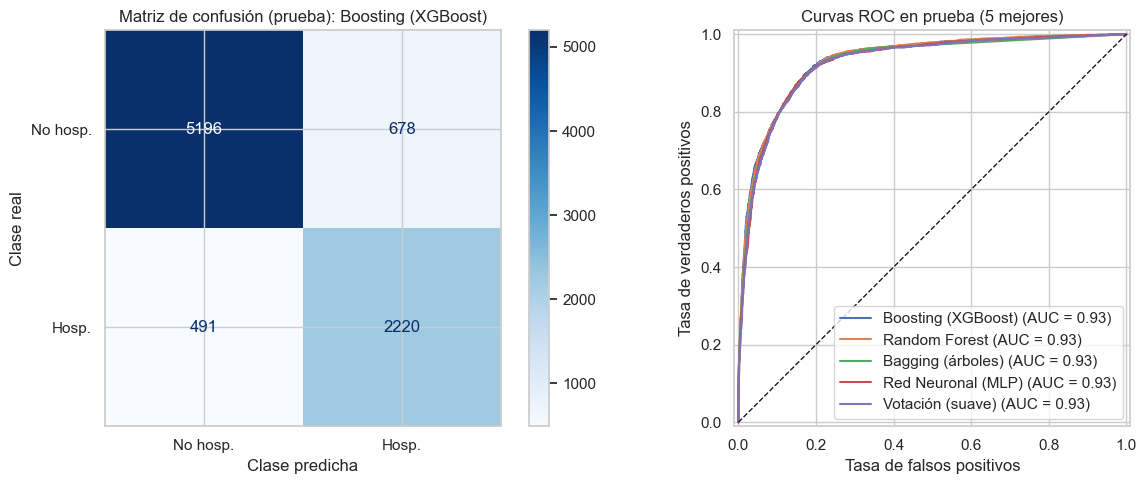

In [35]:
MODELO_FINAL = mejor
pipe_final = finales[MODELO_FINAL]
if not hasattr(pipe_final, "predict_proba"):   # SVC sin probabilidades -> se reentrena con probability=True
    pipe_final = clone(pipe_final).set_params(model__probability=True).fit(X_train, y_train)
print("MODELO SELECCIONADO:", MODELO_FINAL)
print("Hiperparámetros:", busquedas[MODELO_FINAL].best_params_ if MODELO_FINAL in busquedas else top3_aj)
print(classification_report(y_test, preds[MODELO_FINAL], target_names=["No hospitalizado", "Hospitalizado"], digits=4))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, preds[MODELO_FINAL], display_labels=["No hosp.", "Hosp."],
                                        cmap="Blues", ax=ax[0], values_format="d")
ax[0].set_title(f"Matriz de confusión (prueba): {MODELO_FINAL}")
ax[0].set_xlabel("Clase predicha"); ax[0].set_ylabel("Clase real")
for n in ranking_cv[:5]:
    RocCurveDisplay.from_predictions(y_test, probas[n], name=n, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("Curvas ROC en prueba (5 mejores)")
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
guardar_fig("5_matriz_confusion_roc")

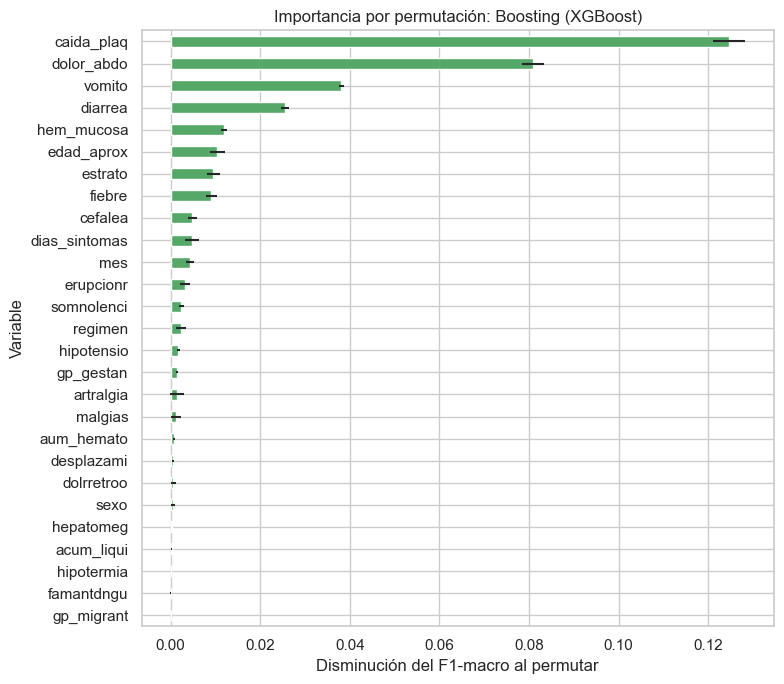

,Variable,Importancia (caída F1),Std
19,caida_plaq,0.1247,0.0036
10,dolor_abdo,0.0809,0.0025
11,vomito,0.0381,0.0006
12,diarrea,0.0255,0.0009
16,hem_mucosa,0.0119,0.0006
0,edad_aprox,0.0104,0.0017
2,estrato,0.0095,0.0014
4,fiebre,0.0091,0.0012
5,cefalea,0.0048,0.0010
1,dias_sintomas,0.0047,0.0016


In [36]:
# Importancia de variables por permutación (en prueba): ¿qué variables usa el modelo?
pi = permutation_importance(pipe_final, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS)
imp = pd.DataFrame({"Variable": FEATURES, "Importancia (caída F1)": pi.importances_mean, "Std": pi.importances_std})
imp = imp.sort_values("Importancia (caída F1)", ascending=False).round(4)
guardar_tabla(imp, "5_importancia")
fig, ax = plt.subplots(figsize=(8, 7))
imp.set_index("Variable")["Importancia (caída F1)"].sort_values().plot.barh(ax=ax, xerr=imp.set_index("Variable")["Std"], color="#55a868")
ax.set_title(f"Importancia por permutación: {MODELO_FINAL}"); ax.set_xlabel("Disminución del F1-macro al permutar")
guardar_fig("5_importancia_variables")
imp.head(10)

**Interpretación de resultados: Importancia de variables.** Las variables más importantes son los signos de alarma de la guía clínica: caída de plaquetas (al permutarla, el F1-macro cae 0,125), dolor abdominal (0,081), vómito (0,038), diarrea (0,026) y hemorragia en mucosas (0,012). Les siguen la edad, el estrato y la fiebre. Esto le da validez clínica al modelo: aprendió los mismos criterios que usa el personal médico, no artefactos de los datos. Variables como famantdngu, hipotermia o gp_migrant no aportan, por su baja frecuencia o su escasa relación con el desenlace.

In [37]:
f1_final = f1_score(y_test, preds[MODELO_FINAL], average="macro")
rec_final = recall_score(y_test, preds[MODELO_FINAL])
objetivos = pd.DataFrame([
    ("F1-macro en prueba mayor o igual a 0.85", round(f1_final, 4), "Cumple" if f1_final >= .85 else "No cumple"),
    ("Recall Hospitalizado mayor o igual a 0.80", round(rec_final, 4), "Cumple" if rec_final >= .80 else "No cumple"),
    ("Al menos 5 clásicos y 3 ensambles comparados con CV", f"{len(clasicos)} + {len(ensambles)}", "Cumple"),
], columns=["Objetivo (Fase 1)", "Resultado", "Estado"])
guardar_tabla(objetivos, "5_objetivos"); objetivos

,Objetivo (Fase 1),Resultado,Estado
0,F1-macro en prueba mayor o igual a 0.85,0.8452,No cumple
1,Recall Hospitalizado mayor o igual a 0.80,0.8189,Cumple
2,Al menos 5 clásicos y 3 ensambles comparados c...,5 + 4,Cumple


---
# FASE 6. Despliegue

### 6.0 Serialización del pipeline completo
Siguiendo el principio del material del curso (*"el preprocesamiento forma parte integral del modelo productivo"*), se serializa **un único objeto `Pipeline`** que contiene imputadores, escalador, codificador one-hot y el modelo. SMOTE solo actúa en `fit`, por lo que en predicción no altera los datos. Junto al modelo se guarda un archivo de **metadatos** (variables, rangos válidos, versiones y métricas) que usa la aplicación.

In [38]:
joblib.dump(pipe_final, "pipeline_dengue.joblib", compress=3)
metadata = {
    "modelo": MODELO_FINAL,
    "hiperparametros": {k.replace("model__", ""): str(v) for k, v in busquedas[MODELO_FINAL].best_params_.items()} if MODELO_FINAL in busquedas else {},
    "features": FEATURES, "num_features": NUM_FEATS, "bin_features": BIN_FEATS, "cat_features": CAT_FEATS,
    "edad_grupos": EDAD_GRUPO, "regimen": {"C": "Contributivo", "S": "Subsidiado", "P": "Excepción", "E": "Especial", "N": "No asegurado", "I": "Indeterminado"},
    "reglas": {"dias_sintomas": [0, 30], "estrato": [1, 6], "mes": [1, 12]},
    "metricas_test": res_test.set_index("Modelo").loc[MODELO_FINAL, ["Accuracy", "Precision", "Recall", "F1", "Recall Hosp.", "ROC-AUC"]].to_dict(),
    "versiones": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
                  "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "dataset": "https://www.datos.gov.co/d/qzc7-jbg3", "n_train": int(len(X_train)), "n_test": int(len(X_test)),
}
Path("model_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Guardado: pipeline_dengue.joblib (%.1f KB) y model_metadata.json" % (Path("pipeline_dengue.joblib").stat().st_size / 1024))

Guardado: pipeline_dengue.joblib (752.3 KB) y model_metadata.json


### 6.1 Predicción con datos nuevos (no usados en el entrenamiento)
Se **recarga el pipeline desde disco** (como lo hará la aplicación) y se predicen **perfiles clínicos nuevos** construidos para validar la lógica del modelo, más registros reales del conjunto de prueba. Se incluye un registro con valores faltantes para comprobar que el pipeline los imputa sin fallar.

In [39]:
modelo_cargado = joblib.load("pipeline_dengue.joblib")
base = {c: 0 for c in BIN_FEATS}
def paciente(**kw):
    r = {"edad_aprox": 24.5, "dias_sintomas": 3, "estrato": 3, "mes": 6, **base, "sexo": "F", "regimen": "C"}
    r.update(kw); return r

nuevos = pd.DataFrame([
    paciente(edad_aprox=24.5, dias_sintomas=2, fiebre=1, cefalea=1, malgias=1),
    paciente(edad_aprox=7, dias_sintomas=5, sexo="M", regimen="S", estrato=1, fiebre=1, dolor_abdo=1, vomito=1, caida_plaq=1),
    paciente(edad_aprox=75, dias_sintomas=4, regimen="S", estrato=2, fiebre=1, caida_plaq=1, aum_hemato=1, somnolenci=1),
    paciente(edad_aprox=34.5, dias_sintomas=3, gp_gestan=1, fiebre=1, cefalea=1, dolor_abdo=1),
    paciente(edad_aprox=17, dias_sintomas=1, sexo="M", estrato=4, fiebre=1, artralgia=1, erupcionr=1),
    paciente(edad_aprox=44.5, dias_sintomas=np.nan, estrato=np.nan, sexo="M", fiebre=1, hem_mucosa=1, caida_plaq=1, vomito=1),
])[FEATURES]
desc_casos = ["Adulto joven, 2 días, solo síntomas leves (fiebre, cefalea, mialgias)",
              "Niño de 5 a 9 años, 5 días, dolor abdominal + vómito + caída de plaquetas",
              "Adulto mayor (70+), 4 días, caída de plaquetas + aumento de hematocrito + somnolencia",
              "Gestante 30 a 39 años, 3 días, fiebre + cefalea + dolor abdominal",
              "Adolescente, 1 día, fiebre + artralgia + erupción",
              "Adulto 40 a 49, días y estrato DESCONOCIDOS, sangrado de mucosas + plaquetas + vómito"]
prob = modelo_cargado.predict_proba(nuevos)[:, 1] if hasattr(modelo_cargado, "predict_proba") else None
pred = modelo_cargado.predict(nuevos)
def interpretar(p):
    if p >= .7: return "Riesgo ALTO: priorizar valoración para hospitalización"
    if p >= .5: return "Riesgo MODERADO-ALTO: probable hospitalización, vigilancia estrecha"
    if p >= .3: return "Riesgo MODERADO: manejo ambulatorio con control a las 24 a 48 h"
    return "Riesgo BAJO: manejo ambulatorio y signos de alarma al paciente"
tabla_61 = pd.DataFrame({"Registro de prueba": desc_casos,
                         "Predicción": np.where(pred == 1, "Hospitalizado", "No hospitalizado"),
                         "Probabilidad hospitalización": np.round(prob, 3),
                         "Interpretación": [interpretar(p) for p in prob]})
guardar_tabla(tabla_61, "6_1_prediccion_nuevos"); tabla_61

,Registro de prueba,Predicción,Probabilidad hospitalización,Interpretación
0,"Adulto joven, 2 días, solo síntomas leves (fie...",No hospitalizado,0.040,Riesgo BAJO: manejo ambulatorio y signos de al...
1,"Niño de 5 a 9 años, 5 días, dolor abdominal + ...",Hospitalizado,0.988,Riesgo ALTO: priorizar valoración para hospita...
2,"Adulto mayor (70+), 4 días, caída de plaquetas...",Hospitalizado,0.961,Riesgo ALTO: priorizar valoración para hospita...
3,"Gestante 30 a 39 años, 3 días, fiebre + cefale...",Hospitalizado,0.805,Riesgo ALTO: priorizar valoración para hospita...
4,"Adolescente, 1 día, fiebre + artralgia + erupción",No hospitalizado,0.048,Riesgo BAJO: manejo ambulatorio y signos de al...
5,"Adulto 40 a 49, días y estrato DESCONOCIDOS, s...",Hospitalizado,0.736,Riesgo ALTO: priorizar valoración para hospita...


**Interpretación de resultados: Predicción con datos nuevos.** El modelo, recargado desde el archivo .joblib, responde de forma coherente con la clínica. Los perfiles con solo síntomas leves (fiebre, cefalea, mialgias o artralgia) reciben una probabilidad de hospitalización menor al 5 % (riesgo bajo, manejo ambulatorio). Los perfiles con signos de alarma, en especial la caída de plaquetas combinada con dolor abdominal o vómito, superan el 95 % en niños y adultos mayores. La gestante con dolor abdominal recibe 0,805, en línea con su condición de grupo de riesgo. El caso con días de síntomas y estrato desconocidos (NaN) se procesa sin errores gracias a la imputación del pipeline (p = 0,736). En los registros reales del conjunto de prueba, el modelo acierta en 5 de 6. El error es un falso positivo (un niño de 5 a 9 años del régimen subsidiado, sin síntomas registrados, que consultó el mismo día), que muestra la influencia del régimen y de los registros incompletos.

In [40]:
# Registros reales del conjunto de prueba (no vistos en entrenamiento)
muestra = X_test.sample(6, random_state=7)
real = pd.DataFrame({"Real": y_test.loc[muestra.index].map({1: "Hospitalizado", 0: "No hospitalizado"}),
                     "Predicho": pd.Series(modelo_cargado.predict(muestra), index=muestra.index).map({1: "Hospitalizado", 0: "No hospitalizado"}),
                     "Prob. hosp.": np.round(modelo_cargado.predict_proba(muestra)[:, 1], 3)})
guardar_tabla(muestra.join(real), "6_1_prediccion_test")
muestra.join(real)

,edad_aprox,dias_sintomas,estrato,mes,fiebre,cefalea,dolrretroo,malgias,artralgia,erupcionr,dolor_abdo,vomito,diarrea,somnolenci,hipotensio,hepatomeg,hem_mucosa,hipotermia,aum_hemato,caida_plaq,acum_liqui,desplazami,famantdngu,gp_gestan,gp_migrant,sexo,regimen,Real,Predicho,Prob. hosp.
22399,54.5,3.0,3.0,7,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,F,C,No hospitalizado,No hospitalizado,0.049
20612,75.0,4.0,4.0,6,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,F,C,Hospitalizado,Hospitalizado,0.853
3882,34.5,3.0,NaN,5,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,No hospitalizado,No hospitalizado,0.023
3089,24.5,3.0,NaN,2,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,M,C,Hospitalizado,Hospitalizado,0.860
7199,7.0,0.0,1.0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,M,S,No hospitalizado,Hospitalizado,0.728
3675,7.0,0.0,NaN,4,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,M,C,No hospitalizado,No hospitalizado,0.046


### 6.2 Aplicación web en Streamlit
La aplicación `app.py` (raíz del repositorio):
1. Carga `pipeline_dengue.joblib` y `model_metadata.json` con `@st.cache_resource`.
2. Recibe los datos del paciente con controles que respetan las **reglas de calidad** (rangos de días, estrato, edad por grupo etario, régimen).
3. Construye un `DataFrame` con las mismas columnas del entrenamiento y llama a `predict_proba`.
4. Muestra el resultado con `st.error` (riesgo alto) o `st.success` (riesgo bajo), la probabilidad y su interpretación.

**Despliegue:** repositorio público en GitHub con `app.py`, `pipeline_dengue.joblib`, `model_metadata.json`, `requirements.txt` (versiones fijadas) y `README.md`, luego share.streamlit.io, luego *New app*, luego `app.py`, luego *Deploy*.

---
# Conclusiones

1. Con la metodología CRISP-DM se construyó, a partir de 28.616 notificaciones del SIVIGILA de Bucaramanga (Datos Abiertos Colombia), un modelo que predice en la primera consulta si un paciente con dengue requerirá hospitalización, con un F1-macro de 0,845 [IC 95 %: 0,837 a 0,854], una Accuracy de 0,864, un ROC-AUC de 0,932 y un Recall de hospitalizados de 0,819.
2. La preparación de los datos fue determinante: eliminar la fuga de información (fec_hos_, conducta, clasfinal, desenlace) evitó un modelo "perfecto" pero inútil, y SMOTE dentro del pipeline elevó el Recall de hospitalizados de 0,667 a 0,851 sin contaminar la validación.
3. Los ensambles de árboles ajustados superaron a los 5 modelos clásicos del curso. XGBoost fue seleccionado por tener el mayor F1-macro en validación cruzada y en prueba, con diferencias estadísticamente significativas en McNemar frente a Random Forest y Bagging.
4. El objetivo de Recall de hospitalizados mayor o igual a 0,80 se cumplió (0,819). El objetivo de F1-macro mayor o igual a 0,85 se alcanzó en validación cruzada (0,849) y quedó a 0,005 en prueba (0,845); el intervalo de confianza incluye 0,85, por lo que la meta está dentro del margen de error estadístico.
5. Las variables más influyentes son los signos de alarma de la guía clínica (caída de plaquetas, dolor abdominal, vómito, diarrea y hemorragia en mucosas), lo que respalda la validez clínica del modelo.
6. El pipeline completo se serializó con joblib y se desplegó en una aplicación Streamlit que recibe datos nuevos, respeta las reglas de calidad y entrega la probabilidad de hospitalización con su interpretación.

### Limitaciones y trabajo futuro
- Deriva temporal: la tasa de hospitalización varió entre el 11,7 % y el 60,4 % según el año. Se recomienda monitorear el desempeño y reentrenar el modelo cada temporada.
- Validez externa: el 96 % de los casos son de Bucaramanga. Antes de usarlo en otras ciudades hay que validarlo con datos locales.
- Grupos minoritarios (migrantes, gestantes, indígenas) con muy pocos casos: conviene evaluar el desempeño por subgrupo (equidad).
- La edad solo está disponible por grupos etarios. Con la edad exacta y variables de laboratorio cuantitativas (conteo de plaquetas, hematocrito) el modelo podría mejorar.
- Trabajo futuro: ajustar el umbral de decisión según el costo clínico de cada error, calibrar las probabilidades y explicar las predicciones individuales con SHAP.